# Модель для предсказания массы морских черепах Chelonia mydas

**Цель:** Разработать модель линейной регрессии для бесконтактного предсказания массы зелёных морских черепах (Chelonia mydas) по их биометрическим данным, полученным системой компьютерного зрения TurtleCV.

# 📊 Проект: Разработка модели линейной регрессии для предсказания массы морских черепах

**TurtleCV - бесконтактное определение массы зелёных морских черепах *Chelonia mydas***

---

# Содержание

1. [Постановка задачи машинного обучения](#task)
2. [Подключение и настройка библиотек](#libraries)
3. [Загрузка датасета](#load_data)
4. [Исследовательский анализ данных](#eda)
   - 4.1 [Данные о каких черепахах представлены?](#data_info)
   - 4.2 [Отбор записей о Chelonia mydas](#filter_cm)
   - 4.3 [Определение полезных признаков](#useful_features)
   - 4.4 [Проверка пропусков и их обработка](#missing_values)
   - 4.5 [Определим дубликаты](#duplicates)
   - 4.6 [Анализ распределений и выбросов](#distributions)
   - 4.7 [Масштаб признаков](#feature_scale)
   - 4.8 [Корреляционный анализ](#correlation)
   - 4.9 [Мультиколлинеарность](#multicollinearity)
5. [Предобработка данных](#preprocessing)
   - 5.1 [Разделение на выборки](#split_data)
   - 5.2 [Обработка пропусков](#handle_missing)
   - 5.3 [Функция стандартизации признаков](#standardization)
   - 5.4 [Функция нормализации признаков](#normalization)
   - 5.5 [Подготовка датасетов из трёх выборок: без масштабирования, с нормализацией, со стандартизацией](#prepare_datasets)
6. [Обучение моделей](#training)
   - 6.1 [Базовая модель (дамми)](#dummy_model)
   - 6.2 [Линейные модели](#linear_models)
   - 6.3 [Бонусное задание](#bonus_task)
   - 6.4 [Итоговая таблица](#results_table)
7. [Сравнение моделей на валидационной выборке](#comparison)
   - 7.1 [Сравнение моделей на валидационной выборке](#val_comparison)
   - 7.2 [Выбор лучшей модели](#best_model)
   - 7.3 [Итоговые выводы](#val_conclusions)
   - 7.4 [Рекомендация по внедрению](#deployment_recommendation)
8. [Проверка лучшей модели на тестовой выборке](#test_evaluation)
   - 8.1 [Проверка модели на лучшей выборке](#test_check)
   - 8.2 [Анализ переобучения](#overfitting_analysis)
   - 8.3 [Проверка требований заказчика](#requirements_check)
9. [Оценка важности признаков](#feature_importance)
   - 9.1 [Важность признаков по абсолютным значениям весов лучшей модели](#weights_importance)
   - 9.2 [Оценка важности признаков лучшей модели](#importance_analysis)
     - 9.2.1 [Ранжирование признаков по важности](#ranking)
     - 9.2.2 [Самые важные признаки](#top_features)
     - 9.2.3 [Интерпретация коэффициентов](#coefficients_interpretation)
     - 9.2.4 [Согласованность с биологией](#biology_consistency)
     - 9.2.5 [Вывод](#importance_conclusion)
10. [Функция для прогнозирования веса черепахи](#prediction_function)
11. [Общие выводы и рекомендации по дальнейшей работе](#conclusions)
    - 11.1 [Какие модели изучены?](#models_studied)
    - 11.2 [Какие результаты получены?](#results_obtained)
    - 11.3 [Рекомендуется ли итоговая модель к внедрению?](#deployment_decision)
    - 11.4 [Какая архитектура и способ обработки признаков показали себя лучше всего?](#best_approach)
    - 11.5 [Какие признаки наиболее важны для модели?](#key_features)
    - 11.6 [Есть ли перспективы у обучения этой или других моделей для предсказания массы других видов черепах?](#future_perspectives)
    - 11.7 [Рекомендации](#final_recommendations)

---

<a id='task'></a>
## Постановка задачи машинного обучения

<font color='#777778'>
- Опишите, какую задачу нужно решить: регрессии или классификации.
    
- Выберите поле, которое станет целевой переменной.
    
- Назовите метрики качества модели, которые планируете использовать.
    
- Опишите критерии успешности проекта с опорой на метрики.
 </font>  

**Описание данных**

Данные содержат следующие поля:

`id` — идентификатор измерения.

`binomial_name` — международное научное название вида черепахи.

`registration number` — регистрационный номер черепахи.

`shell_length` — длина панциря, мм.

`shell_width` — ширина панциря, мм.

`head_length` — длина головы, мм.

`head_width` — ширина головы, мм.

`flipper_length_n` — длина одной ласты, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях вместо n указан номер от 1 до 4.

`flipper_width_n` — ширина одной ласты, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях вместо n указан номер от 1 до 4.

`circle_count` — количество колец роста на панцире черепахи.

`measure_count` — количество измерений, которые произвели, прежде чем усреднить показатели черепахи и добавить их в таблицу.

`shell_crack` — наличие трещин панциря.

`timestamp` — время внесения данных о черепахе.

`weight` — масса черепахи, кг.

**Тип задачи**

Регрессия — необходимо предсказать непрерывное числовое значение (массу черепахи в килограммах).

**Целевая переменная**

`weight` — масса черепахи (кг)

**Метрики качества**

*MAE* Абсолютная ошибка в кг (интерпретируема для заказчика)
*MAPE* Относительная ошибка в % (не зависит от масштаба)
*R²* Доля объяснённой дисперсии

**Критерии успешности**

*MAE ≤ 5 кг* — для черепах массой 50–150 кг (целевая популяция взрослых особей)

*R² ≥ 0.97* на валидационной и тестовой выборках — модель объясняет не менее 97% вариативности массы

*MAPE* — дополнительный контроль качества для черепах разного размера (чем ниже, тем лучше)

Модель — линейная регрессия (интерпретируемые коэффициенты для внедрения в прибор TurtleCV)

Воспроизводимость — фиксированный *random_state=42*

<a id='libraries'></a>
## Подключение и настройка библиотек

<font color='#777778'> В блоке кода ниже, помимо уже указанных библиотек, импортируйте все остальные, которые планируете использовать для проекта. </font>  

In [1]:
import numpy as np
import pandas as pd

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Предобработка данных и разделение выборки
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

# Модели
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

<a id='load_data'></a>
## Загрузка датасета

<font color='#777778'> - Загрузите данные из файла `turtles.csv`, путь к файлу: `'/datasets/turtles.csv'`. При использовании метода [read_csv](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) установите правильные значения для параметров `sep` и `decimal`: в качестве разделителя столбцов используйте символ табуляции (`'\t'`), а в качестве разделителя дробной части — запятую.
- Проверьте, правильно ли прошла загрузка. Данные должны соответствовать описанию в тексте урока.
- С помощью методов библиотеки pandas выведите общие сведения о данных.
- Возможно ли продолжать работу? Если нет — что нужно сделать, чтобы устранить препятствия? </font>  

In [2]:
# Загрузка данных из файла
df = pd.read_csv('/datasets/turtles.csv', sep='\t', decimal=',')

In [3]:
# Вывод общих сведений о данных
df.head()

,id,binomial_name,registration number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
0,20438,Caretta caretta,d89af72662f49ece4d09dec75a8b0166,700.0,381,112.0,82.0,356,205,331,185,270.0,180.0,273.0,144.0,63,3.0,NaN,1703159226,87.687
1,19034,Lepidochelys olivacea,1579c64777de4db1c16e8b7b0d19c45e,341.0,295,65.0,48.0,216,190,229,186,164.0,182.0,180.0,149.0,0,1.0,1.0,1689428175,26.949
2,24689,LEPIDOCHELYS OLIVACEA,bfcec01187569615087e4d777c44985a,408.0,343,71.0,70.0,308,224,285,232,264.0,179.0,268.0,176.0,0,3.0,NaN,1745783111,30.016
3,17945,Lepidochelys Olivacea,2c159675aa28f0ea566fce2090bf4c82,512.0,432,98.0,95.0,334,317,364,284,NaN,NaN,NaN,NaN,3,4.0,1.0,1677757151,33.917
4,24543,lepidochelys olivacea,ecd22499761e2ac56a6d8eb765ec566d,408.0,307,50.0,54.0,280,168,269,218,199.0,165.0,209.0,180.0,0,4.0,1.0,1744455613,28.511


In [4]:
# Информация о данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8861 entries, 0 to 8860
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   8861 non-null   int64  
 1   binomial_name        8812 non-null   object 
 2   registration number  8832 non-null   object 
 3   shell_length         8774 non-null   float64
 4   shell_width          8861 non-null   int64  
 5   head_length          8715 non-null   float64
 6   head_width           8715 non-null   float64
 7   flipper_length_1     8861 non-null   int64  
 8   flipper_width_1      8861 non-null   int64  
 9   flipper_length_2     8861 non-null   int64  
 10  flipper_width_2      8861 non-null   int64  
 11  flipper_length_3     8760 non-null   float64
 12  flipper_width_3      8760 non-null   float64
 13  flipper_length_4     8760 non-null   float64
 14  flipper_width_4      8760 non-null   float64
 15  circle_count         8861 non-null   i

In [5]:
# Статистическое описание числовых столбцов
df.describe()

,id,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
count,8861.000000,8774.000000,8861.000000,8715.000000,8715.000000,8861.000000,8861.000000,8861.000000,8861.000000,8760.000000,8760.000000,8760.000000,8760.000000,8861.000000,8597.000000,2176.000000,8.861000e+03,8842.000000
mean,21359.335628,764.222020,598.832299,123.341021,115.735169,497.551405,380.594515,498.228530,380.687507,397.953196,304.405251,397.853196,305.030023,41.002821,2.477143,1.671415,1.712640e+09,79.163138
std,2263.089420,640.408681,480.970492,67.836566,62.326365,353.575213,214.481679,355.074883,213.485239,282.970532,171.172490,281.983591,171.540535,36.995874,1.116564,1.131790,2.292273e+07,95.877609
min,17438.000000,132.000000,78.000000,19.000000,12.000000,60.000000,34.000000,57.000000,33.000000,50.000000,27.000000,44.000000,25.000000,0.000000,1.000000,1.000000,1.672570e+09,0.000000
25%,19396.000000,440.000000,341.000000,73.000000,67.000000,296.000000,228.000000,296.000000,229.000000,239.000000,182.000000,236.000000,183.000000,0.000000,1.000000,1.000000,1.693001e+09,31.109500
50%,21357.000000,635.000000,487.000000,106.000000,98.000000,416.000000,332.000000,417.000000,330.000000,333.000000,264.000000,333.000000,266.000000,35.000000,2.000000,1.000000,1.712804e+09,41.140500
75%,23317.000000,951.000000,794.000000,158.000000,156.000000,571.000000,493.000000,572.000000,500.000000,457.000000,397.000000,456.000000,396.000000,73.000000,3.000000,2.000000,1.732902e+09,85.239500
max,25279.000000,20240.000000,11550.000000,515.000000,382.000000,2875.000000,1479.000000,2967.000000,1402.000000,2279.000000,1280.000000,2406.000000,1313.000000,178.000000,4.000000,5.000000,1.751608e+09,617.777000


In [6]:
# Проверка на пропуски (null values)
df.isnull().sum()

id                        0
binomial_name            49
registration number      29
shell_length             87
shell_width               0
head_length             146
head_width              146
flipper_length_1          0
flipper_width_1           0
flipper_length_2          0
flipper_width_2           0
flipper_length_3        101
flipper_width_3         101
flipper_length_4        101
flipper_width_4         101
circle_count              0
measure_count           264
shell_crack            6685
timestamp                 0
weight                   19
dtype: int64

In [7]:
# Количество строк и столбцов
df.shape

(8861, 20)

***Промежуточные выводы***

**Качество данных:**

Значительное количество пропусков в shell_crack (75% данных отсутствует), есть выбросы в head_length/width, binomial_name и registration_number, shell_length, flipper_length_3/width_3, flipper_length_4/width_4, measure_count 

Присутствуют выбросы: максимальная длина панциря 20240 мм (20 м) при среднем 764 мм — явная аномалия, требует удаления или исправления (согласно предусловию)

Масса достигает 617 кг при целевом диапазоне 50-150 кг для зелёных черепах — нужна фильтрация по виду

**Целевая переменная (weight):**

19 пропусков

Среднее 79 кг, медиана 41 кг — распределение скошено вправо

Диапазон от 0 до 617 кг

**Признаки:**

Сильный разброс во всех измерениях (например, shell_length от 132 до 20240 мм)

Ласты 3 и 4 имеют меньше данных и тип float64 (возможно, реальные или усреднённые значения)

circle_count от 0 до 178 — возможны ошибки (у зелёной черепахи редко >20-30 колец)

Ограничения по виду:

В данных есть binomial_name, но не все строки заполнены (49 пропусков)

Нужно отфильтровать только Chelonia mydas (зелёная черепаха)

***Вывод: данные требуют правок и очистки — работы над выбросами, фильтрация по виду и массе (50-150 кг), обработка пропусков. Без этого модель не достигнет R² ≥ 0.97 и MAE ≤ 5 кг.***

<a id='eda'></a>
## Исследовательский анализ данных

<font color='#777778'> Проведите исследовательский анализ данных:
1. Выясните, данные о каких черепахах представлены в датасете.
2. Проведите отбор записей о нужном виде черепах. Для дальнейшей работы достаточно изучить только *Chelonia mydas*. При этом вы можете сравнить распределение данных об этих черепахах с другими видами, если есть желание и время.
3. Определите, все ли признаки можно использовать для решения задачи. Ответ обоснуйте. Удалите признаки, которые вам никак не помогут.
4. Проверьте, есть ли в данных пропуски. Определите, какие из них можно обработать сразу, а в каких случаях лучше сперва провести разделение на выборки. Решите, стоит ли удалить некоторые пропуски.
5. Определите, есть ли в данных дубликаты. Выберите корректный способ их обработки.
6. Проанализируйте распределение признаков, постройте необходимые для этого визуализации: ящики с усами, гистограммы и так далее. Определите, есть ли в данных выбросы и какие из них критичные. Решите, можно ли их сразу исправить.
7. Проверьте, одинаков ли масштаб признаков. Если он различается, предложите решение этой проблемы.
8. Проанализируйте корреляцию между признаками и целевой переменной с помощью вычислений и графически. Определите, все ли признаки нужны для дальнейшей работы.
9. Проверьте данные на мультиколлинеарность и решите, можно ли её устранить.</font>  

<a id='data_info'></a>
### Данные о каких черепахах представлены?

In [8]:
# Проверка уникальных видов
df['binomial_name'].unique()

array(['Caretta caretta', 'Lepidochelys olivacea',
       'LEPIDOCHELYS OLIVACEA', 'Lepidochelys Olivacea',
       'lepidochelys olivacea', 'Chelonia mydas',
       'ERETMOCHELYS IMBRICATA', 'Eretmochelys imbricata',
       'Dermochelys coriacea', 'caretta caretta', 'CARETTA CARETTA',
       'chelonia mydas', 'Chelonia Mydas', 'CHELONIA MYDAS',
       'Dermochelys Coriacea', 'eretmochelys imbricata', nan,
       'Caretta Caretta', 'lepidochelys kempii', 'Lepidochelys kempii',
       'Eretmochelys Imbricata', 'dermochelys coriacea',
       'Lepidochelys Kempii', 'DERMOCHELYS CORIACEA'], dtype=object)

In [9]:
# Количество записей по видам

df['binomial_name'].value_counts()

Lepidochelys olivacea     3372
Chelonia mydas            2325
Caretta caretta            674
lepidochelys olivacea      416
Dermochelys coriacea       399
Eretmochelys imbricata     332
Lepidochelys Olivacea      285
chelonia mydas             252
Chelonia Mydas             177
LEPIDOCHELYS OLIVACEA      142
caretta caretta             90
CHELONIA MYDAS              75
Caretta Caretta             46
eretmochelys imbricata      41
dermochelys coriacea        40
CARETTA CARETTA             37
Eretmochelys Imbricata      28
Dermochelys Coriacea        27
Lepidochelys kempii         22
DERMOCHELYS CORIACEA        18
ERETMOCHELYS IMBRICATA       8
Lepidochelys Kempii          3
lepidochelys kempii          3
Name: binomial_name, dtype: int64

*Здесь мы видим наличие строк с интересующим нас видом, но выполненных в разных регистрах: (Chelonia mydas, chelonia mydas и т.д.)*

<a id='filter_cm'></a>
### Отбор записей о Chelonia mydas

In [10]:
# Приводим к нижнему регистру для единообразия
df['binomial_name'] = df['binomial_name'].str.lower().str.strip()

# Отбираем только Chelonia mydas
df_mydas = df[df['binomial_name'] == 'chelonia mydas'].copy()

print(f"Записей о Chelonia mydas: {len(df_mydas)}")

Записей о Chelonia mydas: 2829


<a id='useful_features'></a>
### Определение полезных признаков

In [11]:
# Анализируем признаки
df_mydas.columns.tolist()

['id',
 'binomial_name',
 'registration number',
 'shell_length',
 'shell_width',
 'head_length',
 'head_width',
 'flipper_length_1',
 'flipper_width_1',
 'flipper_length_2',
 'flipper_width_2',
 'flipper_length_3',
 'flipper_width_3',
 'flipper_length_4',
 'flipper_width_4',
 'circle_count',
 'measure_count',
 'shell_crack',
 'timestamp',
 'weight']

*В данном случае столбцы 'id', 'registration number', 'timestamp', 'binomial_name' нам не интересны в рамках проводимого исследования, поскольку не передают качественных или количественных данных. 'measure_count' отображает количество измерений - этот параметр показывает лишь качество замера, но в рамках исследования создаст лишний шум*

In [12]:
# Переносим 'id' в индекс, остальные ненужные столбцы удаляем
cols_to_drop = ['registration number', 'timestamp', 'binomial_name', 'measure_count']

# Устанавливаем 'id' как индекс
df_mydas = df_mydas.set_index('id')

# Удаляем остальные ненужные столбцы
df_mydas = df_mydas.drop(columns=cols_to_drop)

print(f"\n'id' перенесён в индекс датафрейма")
print(f"Удалены столбцы: {cols_to_drop}")
print(f"Оставлено столбцов: {df_mydas.shape[1]}")
print(f"Индекс датафрейма: {df_mydas.index.name}")


'id' перенесён в индекс датафрейма
Удалены столбцы: ['registration number', 'timestamp', 'binomial_name', 'measure_count']
Оставлено столбцов: 15
Индекс датафрейма: id


In [13]:
df_mydas.columns.tolist()

['shell_length',
 'shell_width',
 'head_length',
 'head_width',
 'flipper_length_1',
 'flipper_width_1',
 'flipper_length_2',
 'flipper_width_2',
 'flipper_length_3',
 'flipper_width_3',
 'flipper_length_4',
 'flipper_width_4',
 'circle_count',
 'shell_crack',
 'weight']

<a id='missing_values'></a>
### Проверка пропусков и их обработка

In [14]:
# Пропуски в данных Chelonia mydas ДО обработки
df_mydas.isnull().sum()

shell_length          35
shell_width            0
head_length           39
head_width            39
flipper_length_1       0
flipper_width_1        0
flipper_length_2       0
flipper_width_2        0
flipper_length_3      31
flipper_width_3       31
flipper_length_4      31
flipper_width_4       31
circle_count           0
shell_crack         2152
weight                 3
dtype: int64

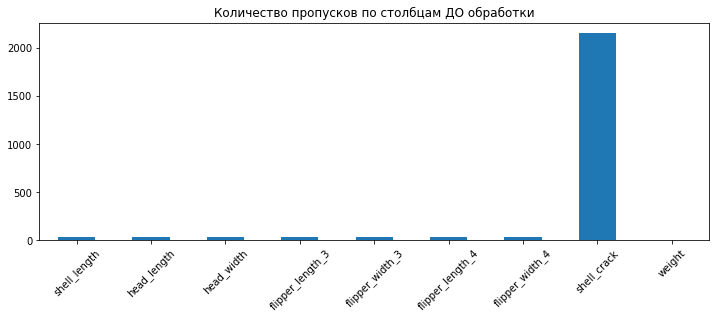

In [15]:
# Визуализация пропусков
plt.figure(figsize=(12, 4))
missing = df_mydas.isnull().sum()
missing[missing > 0].plot(kind='bar')
plt.title('Количество пропусков по столбцам ДО обработки')
plt.xticks(rotation=45)
plt.show()

In [16]:
# ОБРАБОТКА ПРОПУСКОВ
print(f"До удаления пропусков: {len(df_mydas)} записей")

До удаления пропусков: 2829 записей


In [17]:
# Удаляем строки с пропусками в целевой переменной weight
df_mydas = df_mydas.dropna(subset=['weight'])

print(f"После удаления пропусков: {len(df_mydas)} записей")

После удаления пропусков: 2826 записей


*В случае с признаками 'shell_length', 'head_width','flipper_length_3', 'flipper_width_3', 'flipper_length_4', 'flipper_width_4' сложно заведомо сказать, с чем связано наличие пропусков, но на последующих этапах пропуски можно будет заменить медианными или близкими по смыслу значениями соответствующих признаков. В случае с 'shell_crack' количество пропусков значительно (порядка 3/4 от всех значений). Можно предположить, что в пропущенных значечния не было обнаружено трещин на панцире, а потому в пропущенных значениях можно проставить 0. В целом наличие трещин говорит о возможных травмах, что незначительно могло сказаться на здоровье и весе черепахи. Учитывая это, можно было бы удалить этот параметр, но он все же может оказывать влияние на целевую переменную.*

In [18]:
# Для shell_crack заполняем пропуски значением 0
df_mydas['shell_crack'] = df_mydas['shell_crack'].fillna(0)

# Пропуски в данных Chelonia mydas ПОСЛЕ обработки
df_mydas.isnull().sum()

shell_length        35
shell_width          0
head_length         39
head_width          39
flipper_length_1     0
flipper_width_1      0
flipper_length_2     0
flipper_width_2      0
flipper_length_3    31
flipper_width_3     31
flipper_length_4    31
flipper_width_4     31
circle_count         0
shell_crack          0
weight               0
dtype: int64

<a id='duplicates'></a>
### Определим дубликаты

In [19]:
# Дубликаты

df_mydas.duplicated().sum()

340

*В датасете есть 340 полных дубликатов. Удалим их, поскольку их наличие спровоцирует переобучение модели. Неявные дубликаты обнаружить невозможно, исходя из заданных условий задачи.*

In [20]:
# Удаляем дубликаты
df_mydas = df_mydas.drop_duplicates()

print(f"После удаления дубликатов: {len(df_mydas)} записей")

После удаления дубликатов: 2486 записей


<a id='distributions'></a>
### Анализ распределений и выбросов

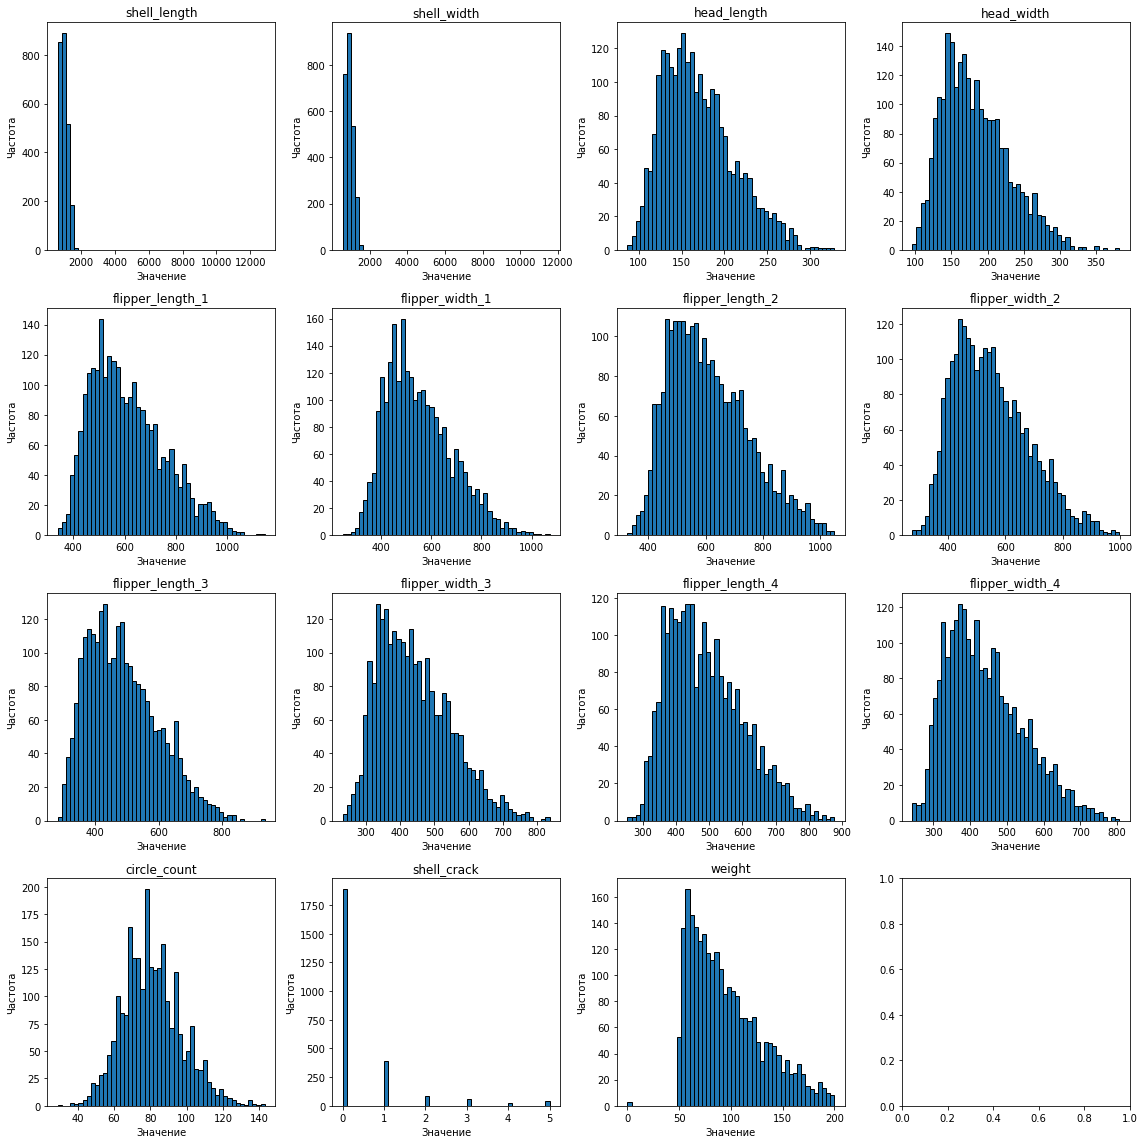

In [21]:
# Гистограммы для всех числовых признаков
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()

numeric_cols = df_mydas.select_dtypes(include=[np.number]).columns
for i, col in enumerate(numeric_cols):
    if i < len(axes):
        axes[i].hist(df_mydas[col].dropna(), bins=50, edgecolor='black')
        axes[i].set_title(col)
        axes[i].set_xlabel('Значение')
        axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

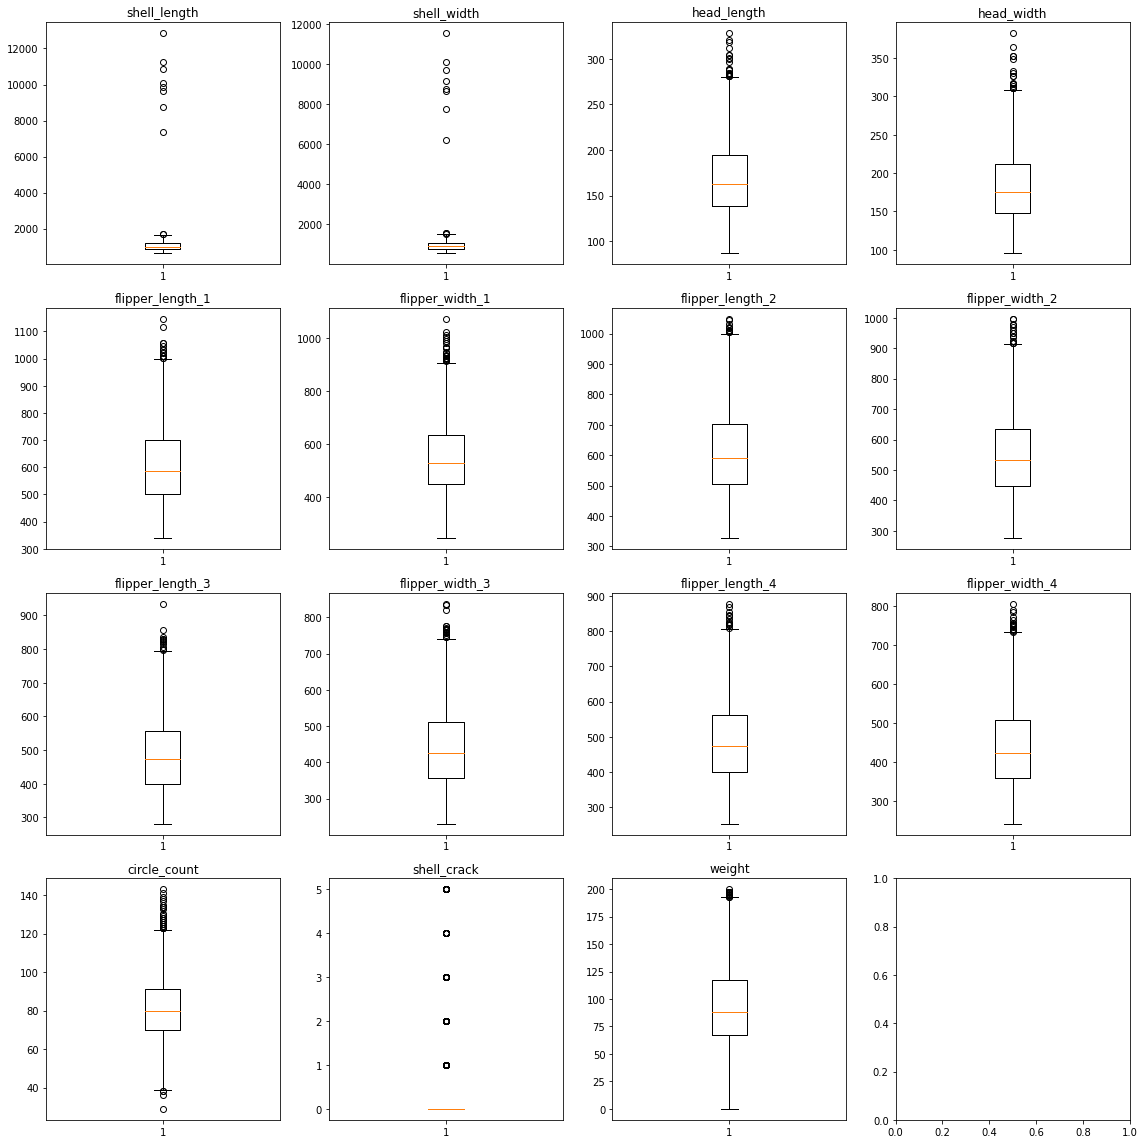

In [22]:
# Ящики с усами для выявления выбросов
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    if i < len(axes):
        axes[i].boxplot(df_mydas[col].dropna())
        axes[i].set_title(col)

plt.tight_layout()
plt.show()


*Здесь мы видим наличие ярко выраженных выбросов в 'shell_length' и 'shell_width'. Вероятно, это и есть те ошибки, которые сделали замерщики. Инфомация из источнико говорит, что длина панциря у взрослых особей Chelonia mydas достигает размера 150 см (1500 мм). Ширина — 130 см (1300 мм). Редко длина достигает значения 2000 мм. Поделим завышенные значения на 10 исходя из того, что максимальная длина панциря черепах Chelonia mydas составляет 2000 мм, ширина — 1700 мм*

In [23]:
# ИСПРАВЛЕНИЕ ВЫБРОСОВ
print(f"Размер ДО обработки выбросов: {len(df_mydas)}")

# ШАГ 1: Определяем аномальные значения в shell_length и shell_width

outliers_multiplied_length = df_mydas['shell_length'] > 2000
outliers_multiplied_width = df_mydas['shell_width'] > 1700

print(f"\nЗначений shell_length > 2000 (умножены на 10): {outliers_multiplied_length.sum()}")
print(f"Значений shell_width > 1700 (умножены на 10): {outliers_multiplied_width.sum()}")


Размер ДО обработки выбросов: 2486

Значений shell_length > 2000 (умножены на 10): 8
Значений shell_width > 1700 (умножены на 10): 8


In [24]:
# ШАГ 2: Исправляем ошибку волонтёра - делим на 10
df_mydas.loc[outliers_multiplied_length, 'shell_length'] = df_mydas.loc[outliers_multiplied_length, 'shell_length'] / 10
df_mydas.loc[outliers_multiplied_width, 'shell_width'] = df_mydas.loc[outliers_multiplied_width, 'shell_width'] / 10

print(f"\nПосле исправления ошибки умножения (деление на 10):")
print(f"  Макс shell_length: {df_mydas['shell_length'].max():.0f} мм")
print(f"  Макс shell_width: {df_mydas['shell_width'].max():.0f} мм")


После исправления ошибки умножения (деление на 10):
  Макс shell_length: 1683 мм
  Макс shell_width: 1554 мм


*После деления на 10 значения длины и ширины панциря соответствуют биологическим размерам Chelonia mydas. Удаление крупных особей не требуется — это естественная вариативность вида.*

*Проанализируем значения 'weight'. В данных есть нулевые значения массы — это явная ошибка. Удалим только их. Аномально высокие значения (> 200 кг) оставим — это биологическая вариативность, информации о неверном взвешивании нет.*

In [25]:
# ШАГ 5: Удаляем только нулевые значения weight (явная ошибка данных)
outliers_weight = df_mydas['weight'] == 0
if outliers_weight.sum() > 0:
    print(f"\nНулевых значений weight: {outliers_weight.sum()}")
    df_mydas = df_mydas[~outliers_weight]
    print(f"Удалены строки с нулевой массой")

print(f"\nРазмер ПОСЛЕ полной обработки: {len(df_mydas)}")


Нулевых значений weight: 3
Удалены строки с нулевой массой

Размер ПОСЛЕ полной обработки: 2483


*Итоговая выборка соответствует справочной литературе. Отдельно посмотрим, как выглядят диаграммы распределения и ящик с усами 'shell_length' и 'shell_width' после обработки.*

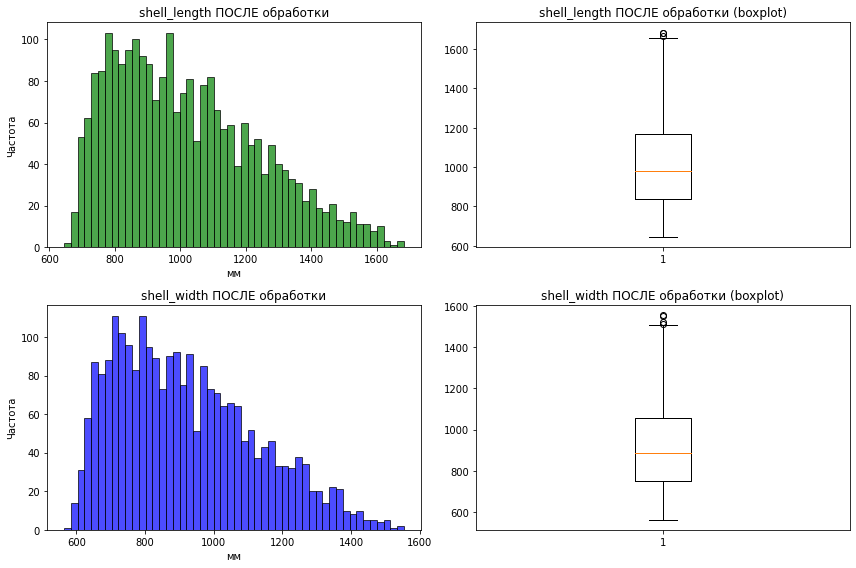

In [26]:
# Визуализация ПОСЛЕ полной обработки
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].hist(df_mydas['shell_length'], bins=50, edgecolor='black', color='green', alpha=0.7)
axes[0,0].set_title('shell_length ПОСЛЕ обработки')
axes[0,0].set_xlabel('мм')
axes[0,0].set_ylabel('Частота')

axes[0,1].boxplot(df_mydas['shell_length'].dropna())
axes[0,1].set_title('shell_length ПОСЛЕ обработки (boxplot)')

axes[1,0].hist(df_mydas['shell_width'], bins=50, edgecolor='black', color='blue', alpha=0.7)
axes[1,0].set_title('shell_width ПОСЛЕ обработки')
axes[1,0].set_xlabel('мм')
axes[1,0].set_ylabel('Частота')

axes[1,1].boxplot(df_mydas['shell_width'].dropna())
axes[1,1].set_title('shell_width ПОСЛЕ обработки (boxplot)')

plt.tight_layout()
plt.show()



*Правый край 'shell_length' более пологий, чем 'shell_width'. Это естественная вариативность размеров; дополнительная обработка не требуется*

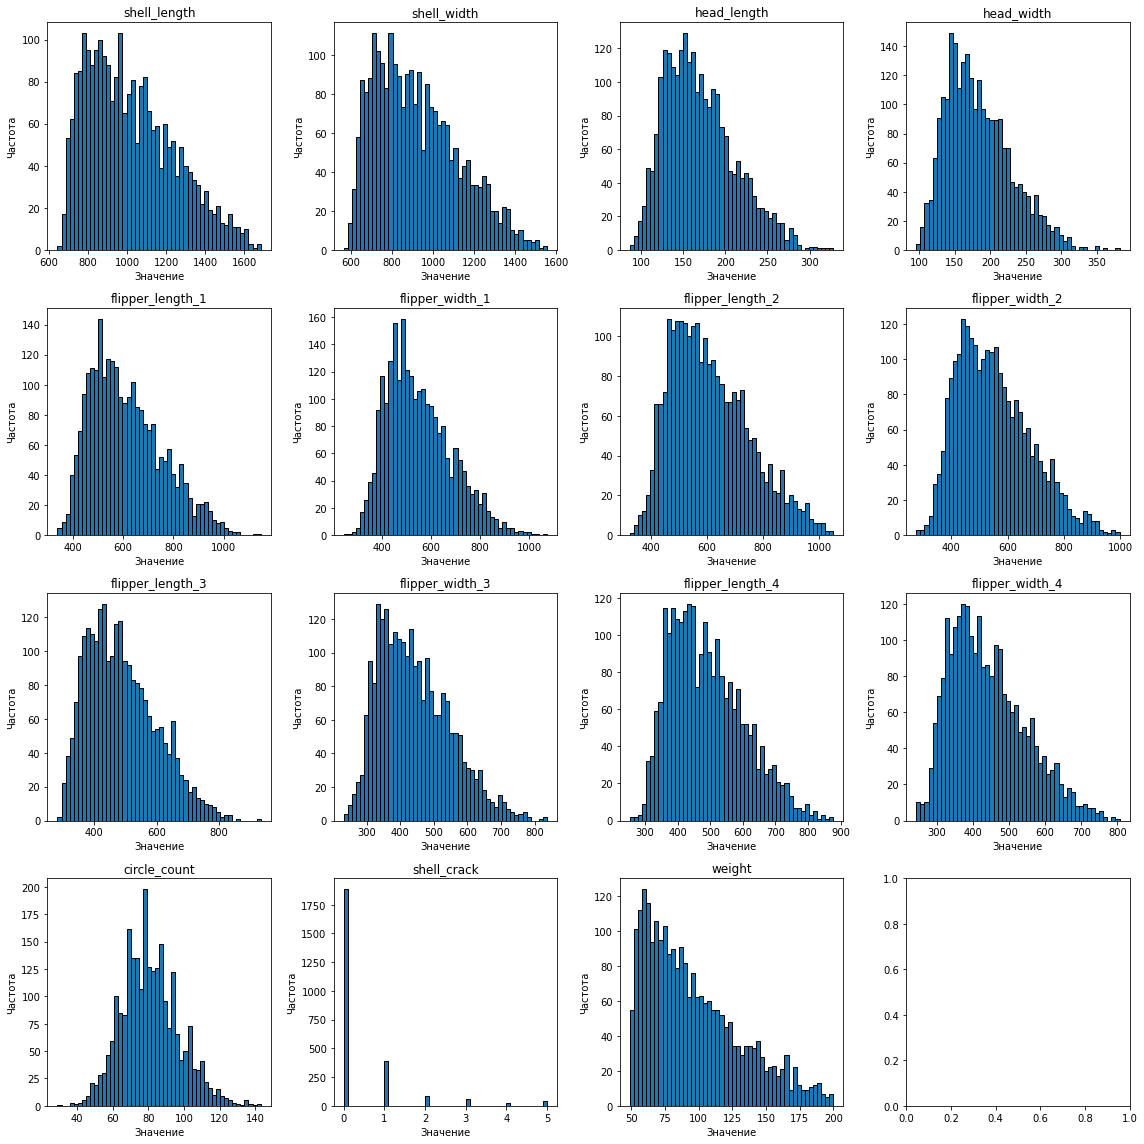

In [27]:
# Гистограммы для всех числовых признаков
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()

numeric_cols = df_mydas.select_dtypes(include=[np.number]).columns
for i, col in enumerate(numeric_cols):
    if i < len(axes):
        axes[i].hist(df_mydas[col].dropna(), bins=50, edgecolor='black')
        axes[i].set_title(col)
        axes[i].set_xlabel('Значение')
        axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()


*Визуально графики говорят о достоверности данных.*

<a id='feature_scale'></a>
### Масштаб признаков

In [28]:
# Проверка масштаба
stats = df_mydas[numeric_cols].describe().loc[['min', 'max', 'mean', 'std']]
stats

,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,shell_crack,weight
min,645.000000,564.000000,87.000000,96.000000,339.000000,245.000000,327.000000,276.000000,282.000000,231.000000,254.000000,243.000000,29.000000,0.000000,49.045000
max,1683.000000,1554.000000,328.000000,382.000000,1147.000000,1072.000000,1049.000000,997.000000,934.000000,837.000000,877.000000,806.000000,143.000000,5.000000,199.961000
mean,1018.386308,918.886830,169.714461,183.311683,611.919855,549.349577,611.838905,550.203786,487.223716,440.602689,489.198452,440.934800,80.923882,0.420056,96.184925
std,222.000308,203.164503,41.305333,45.467571,142.471085,131.829439,138.925759,130.881637,110.375589,105.505774,112.575107,104.512015,16.227341,0.960728,35.011526


*Видим существенные (кратные) различия между 'shell_length', 'circle_count' и 'shell_crack'. В дальнейшем необходимо будет произвести работу по масштабированию данных.*

<a id='correlation'></a>
### Корреляционный анализ

In [29]:
# Корреляция с целевой переменной
correlations = df_mydas[numeric_cols].corr()['weight'].sort_values(ascending=False)
correlations

weight              1.000000
shell_length        0.984461
shell_width         0.968626
flipper_length_1    0.927451
flipper_length_2    0.923784
flipper_length_4    0.923569
flipper_length_3    0.922198
flipper_width_2     0.903030
flipper_width_4     0.902358
flipper_width_3     0.901860
flipper_width_1     0.897135
head_length         0.875362
head_width          0.868456
circle_count        0.510257
shell_crack         0.171192
Name: weight, dtype: float64

*Из приведенных данных видно, что целевая переменная 'weight' главным образом коррелирует с зоометрическими данными (размеры панциря, лап, головы) черепах (0,84-0,98). В меньшей степени 'weight' коррелирует с количеством колец на панцирпе (0,51), еще меньше — с количеством трещин и царапин на панцире (0,17).*

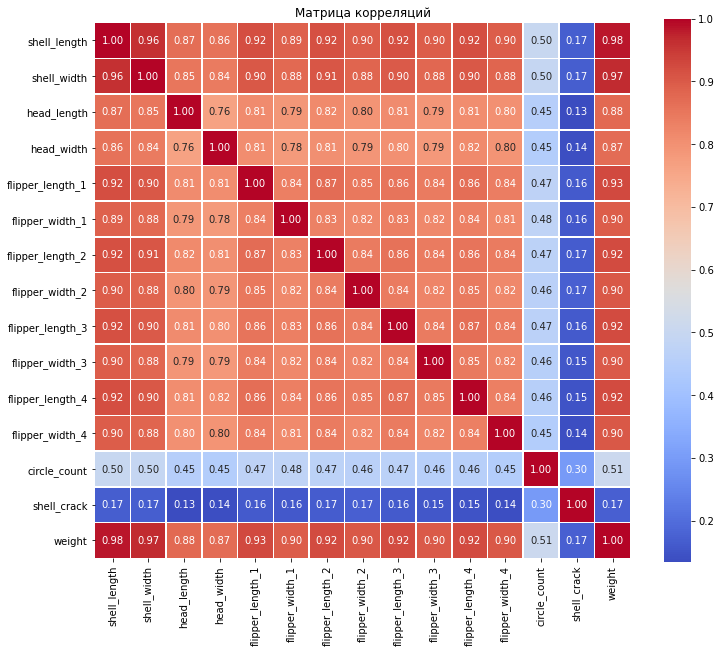

In [30]:
# Тепловая карта корреляций
plt.figure(figsize=(12, 10))
sns.heatmap(df_mydas[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', 
            square=True, linewidths=0.5)
plt.title('Матрица корреляций')
plt.show()

<a id='multicollinearity'></a>
### Мультиколлинеарность

*Мультиколлинеарность между размерами ласт. Поскольку мы используем Ridge-регуляризацию (L2), которая устойчива к коллинеарности, все ласты оставляем в признаковом пространстве.*

In [31]:
# Итоговая проверка готовности данных
print(f"Количество записей: {len(df_mydas)}")
print(f"Количество признаков: {df_mydas.shape[1] - 1}")  # минус weight
print(f"Пропуски: {df_mydas.isnull().sum().sum()}")

Количество записей: 2483
Количество признаков: 14
Пропуски: 215


***Данные готовы для разделения на выборки и обучения модели!***

<a id='preprocessing'></a>
## Предобработка данных

<font color='#777778'> 
1. Разделите данные на выборки: обучающую (60%), валидационную (20%) и тестовую (20%). В реальных проектах стараются писать код предобработки так, чтобы предотвратить утечку данных. Это проще сделать, если сразу поделить данные.
    
2. Обработайте пропуски. При необходимости заполните их средними (медианными) значениями. Рассчитайте заполнитель только по обучающей выборке: это ещё одно правило для предотвращения утечки.
    
3. Напишите функцию для стандартизации признаков. Расчёт параметров масштабирования делайте только по обучающей выборке, чтобы не дать утечке ни малейшего шанса.
    
4. Напишите функцию для нормализации признаков.
    
5. Подготовьте несколько датасетов из трёх выборок каждый для дальнейшего обучения моделей с разным способом масштабирования: без масштабирования, с нормализацией, со стандартизацией.</font>

<a id='split_data'></a>
### Разделение на выборки

In [32]:
# Исходные данные (после всех предыдущих обработок)
# df_mydas содержит признаки: ['shell_length', 'shell_width', 'head_length', 'head_width','flipper_length_1','flipper_width_1',
# 'flipper_length_2','flipper_width_2','flipper_length_3','flipper_width_3', 'flipper_length_4','flipper_width_4','circle_count',
# 'shell_crack']

# РАЗДЕЛЕНИЕ НА ВЫБОРКИ 
# Обучающая 60%, валидационная 20%, тестовая 20%

X = df_mydas.drop('weight', axis=1)
y = df_mydas['weight']

# Шаг 1: Выделяем train_val (80%) и test (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,           # 20% на тест
    shuffle=True,
    random_state=42
)

# Шаг 2: Из train_val (80%) выделяем train (75% от 80% = 60%) и val (25% от 80% = 20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,          # 25% от 80% = 20% от исходных
    shuffle=True,
    random_state=42
)

print(f"\n РАЗМЕРЫ ВЫБОРОК:")
print(f"   Исходный датасет: {len(df_mydas)} записей (100%)")
print(f"   Обучающая (train): {len(X_train)} записей ({len(X_train)/len(df_mydas)*100:.0f}%)")
print(f"   Валидационная (val): {len(X_val)} записей ({len(X_val)/len(df_mydas)*100:.0f}%)")
print(f"   Тестовая (test): {len(X_test)} записей ({len(X_test)/len(df_mydas)*100:.0f}%)")
print(f"\n   Проверка: train ({len(X_train)}) + val ({len(X_val)}) + test ({len(X_test)}) = {len(X_train)+len(X_val)+len(X_test)}")


 РАЗМЕРЫ ВЫБОРОК:
   Исходный датасет: 2483 записей (100%)
   Обучающая (train): 1489 записей (60%)
   Валидационная (val): 497 записей (20%)
   Тестовая (test): 497 записей (20%)

   Проверка: train (1489) + val (497) + test (497) = 2483


<a id='handle_missing'></a>
### Обработка пропусков

*На предыдущем этапе мы оставили несколько пропусков, которые заполним средними значениями по обучающей выборке*

In [33]:
# ОБРАБОТКА ПРОПУСКОВ
print(f"\n ПРОВЕРКА ПРОПУСКОВ:")
print("Пропуски в train:")
display(X_train.isnull().sum())
print("Пропуски в val:")
display(X_val.isnull().sum())
print("Пропуски в test:")
display(X_test.isnull().sum())


 ПРОВЕРКА ПРОПУСКОВ:
Пропуски в train:


shell_length        14
shell_width          0
head_length         22
head_width          22
flipper_length_1     0
flipper_width_1      0
flipper_length_2     0
flipper_width_2      0
flipper_length_3    14
flipper_width_3     14
flipper_length_4    14
flipper_width_4     14
circle_count         0
shell_crack          0
dtype: int64

Пропуски в val:


shell_length        10
shell_width          0
head_length          8
head_width           8
flipper_length_1     0
flipper_width_1      0
flipper_length_2     0
flipper_width_2      0
flipper_length_3     6
flipper_width_3      6
flipper_length_4     6
flipper_width_4      6
circle_count         0
shell_crack          0
dtype: int64

Пропуски в test:


shell_length        5
shell_width         0
head_length         5
head_width          5
flipper_length_1    0
flipper_width_1     0
flipper_length_2    0
flipper_width_2     0
flipper_length_3    9
flipper_width_3     9
flipper_length_4    9
flipper_width_4     9
circle_count        0
shell_crack         0
dtype: int64

In [34]:
# Заполняем пропуски медианными значениями (только по обучающей выборке!)
# Находим медианные значения для каждого признака на train
median_values = X_train.median()

# Применяем эти медианы ко всем выборкам
X_train = X_train.fillna(median_values)
X_val = X_val.fillna(median_values)
X_test = X_test.fillna(median_values)

print(f"\n   Пропуски заполнены медианными значениями из train:")
for col in median_values.index:
    print(f"      {col}: {median_values[col]:.2f}")


   Пропуски заполнены медианными значениями из train:
      shell_length: 966.00
      shell_width: 878.00
      head_length: 162.00
      head_width: 175.00
      flipper_length_1: 583.00
      flipper_width_1: 520.00
      flipper_length_2: 584.00
      flipper_width_2: 529.00
      flipper_length_3: 469.00
      flipper_width_3: 421.00
      flipper_length_4: 469.00
      flipper_width_4: 419.00
      circle_count: 80.00
      shell_crack: 0.00


<a id='standardization'></a>
### Функция стандартизации признаков

*Расчёт параметров масштабирования делайте только по обучающей выборке.*

In [35]:
# ФУНКЦИЯ СТАНДАРТИЗАЦИИ (StandardScaler)
def standardize_data(X_train, X_val, X_test):
    """
    Стандартизация признаков (Z-нормализация)
    Формула: X_scaled = (X - mean) / std
    Результат: mean = 0, std = 1
    """
    scaler = StandardScaler()
    
    # Обучаем только на train
    X_train_scaled = scaler.fit_transform(X_train)
    
    # Преобразуем val и test
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_val_scaled, X_test_scaled, scaler

<a id='normalization'></a>
### Функция нормализации признаков

In [36]:
# ФУНКЦИЯ НОРМАЛИЗАЦИИ (MinMaxScaler)
def normalize_data(X_train, X_val, X_test):
    """
    Нормализация признаков (MinMaxScaler)
    Формула: X_scaled = (X - min) / (max - min)
    Результат: диапазон [0, 1]
    """
    scaler = MinMaxScaler()
    
    # Обучаем только на train
    X_train_scaled = scaler.fit_transform(X_train)
    
    # Преобразуем val и test
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_val_scaled, X_test_scaled, scaler

<a id='prepare_datasets'></a>
### Подготовка датасетов из трёх выборок: без масштабирования, с нормализацией, со стандартизацией

In [37]:
# Вариант 1: Без масштабирования
X_train_raw = X_train.values
X_val_raw = X_val.values
X_test_raw = X_test.values
y_train_raw = y_train.values
y_val_raw = y_val.values
y_test_raw = y_test.values

# Вариант 2: С нормализацией (MinMaxScaler)
X_train_norm, X_val_norm, X_test_norm, scaler_norm = normalize_data(X_train, X_val, X_test)

# Вариант 3: Со стандартизацией (StandardScaler)
X_train_std, X_val_std, X_test_std, scaler_std = standardize_data(X_train, X_val, X_test)

**ДАТАСЕТЫ ПОДГОТОВЛЕНЫ:**

   Датасет 1: БЕЗ масштабирования (исходные данные)
   
   Датасет 2: С нормализацией (MinMaxScaler) - диапазон [0, 1]
   
   Датасет 3: Со стандартизацией (StandardScaler) - mean=0, std=1

**Проверка результатов масштабирования**

In [38]:
# ПРОВЕРКА РЕЗУЛЬТАТОВ МАСШТАБИРОВАНИЯ
print(f"\n ПРОВЕРКА МАСШТАБИРОВАНИЯ (на примере shell_length):")

# Исходные данные
print(f"\n   БЕЗ масштабирования:")
print(f"      min: {X_train['shell_length'].min():.2f}, max: {X_train['shell_length'].max():.2f}, mean: {X_train['shell_length'].mean():.2f}, std: {X_train['shell_length'].std():.2f}")

# Нормализация (MinMax)
norm_col_idx = list(X_train.columns).index('shell_length')
norm_values = X_train_norm[:, norm_col_idx]
print(f"\n   ПОСЛЕ нормализации (MinMax):")
print(f"      min: {norm_values.min():.3f}, max: {norm_values.max():.3f}, mean: {norm_values.mean():.3f}, std: {norm_values.std():.3f}")

# Стандартизация (Standard)
std_values = X_train_std[:, norm_col_idx]
print(f"\n   ПОСЛЕ стандартизации (Standard):")
print(f"      min: {std_values.min():.3f}, max: {std_values.max():.3f}, mean: {std_values.mean():.3f}, std: {std_values.std():.3f}")




 ПРОВЕРКА МАСШТАБИРОВАНИЯ (на примере shell_length):

   БЕЗ масштабирования:
      min: 645.00, max: 1683.00, mean: 1011.45, std: 220.47

   ПОСЛЕ нормализации (MinMax):
      min: 0.000, max: 1.000, mean: 0.353, std: 0.212

   ПОСЛЕ стандартизации (Standard):
      min: -1.663, max: 3.047, mean: 0.000, std: 1.000


**ИТОГОВЫЙ РЕЗУЛЬТАТ ПРЕДОБРАБОТКИ**


Подготовлены 3 датасета для обучения моделей:

1. БЕЗ масштабирования:

   - X_train_raw, X_val_raw, X_test_raw

   - y_train_raw, y_val_raw, y_test_raw


2. С нормализацией (MinMaxScaler):
   
   - X_train_norm, X_val_norm, X_test_norm
   
   - y_train_raw, y_val_raw, y_test_raw


3. Со стандартизацией (StandardScaler):
   
   - X_train_std, X_val_std, X_test_std
   
   - y_train_raw, y_val_raw, y_test_raw


Все преобразования выполнены без утечки данных:

- Параметры масштабирования вычислены ТОЛЬКО на train

- Пропуски заполнены средними ТОЛЬКО из train

- Разделение выполнено по правилу: train 60%, val 20%, test 20%


<a id='training'></a>
## Обучение моделей

<font color='#777778'>
1. Постройте базовую модель (дамми), с которой будете сравнивать все остальные. Если они будут хуже базовой по качеству, это будет означать, что при обучении что-то пошло не так. Пример дамми: модель, которая всегда предсказывает среднее значение целевой переменной из обучающей выборки.

    2. Обучите несколько архитектур линейных моделей. Они могут различаться по ряду черт: набором отобранных признаков, масштабом признаков, установленными гиперпараметрами, функциями потерь. Попробуйте обучить следующие модели:
   - `LinearRegression`;
   - `Lasso` (L1-регуляризация);
   - `Ridge` (L2-регуляризация);
   - `SGDRegressor`.
   
   Обязательно попробуйте модели с разными значениями гиперпараметра `loss`.
- **Бонусное задание.** Подумайте, можно ли улучшить модели за счёт создания новых признаков: например, умножив длину ласт на ширину. Проверьте, усилится ли корреляция нового признака с целевой переменной, возрастёт ли благодаря ему качество модели.
3. Сформируйте итоговую таблицу с результатами моделей. Это удобно сделать в виде датафрейма pandas. Включите в таблицу следующие столбцы:
   - Название модели.
   - Название датасета — оно должно указывать на то, какой способ масштабирования использовался при подготовке данных.
   - Метрики качества, рассчитанные на валидационной выборке. Основная метрика — MAE, дополнительные — MSE, R², MAPE и прочие.</font>

**Построим функции расчета метрик качества**

In [39]:
# --- ФУНКЦИИ ---
def calculate_metrics(y_true, y_pred):
    """Расчёт метрик качества"""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    r2 = r2_score(y_true, y_pred)
    return {'MAE': round(mae, 2), 'MSE': round(mse, 2), 'RMSE': round(rmse, 2), 
            'MAPE': round(mape, 2), 'R2': round(r2, 3)}

<font color='#777778'>
1. Постройте базовую модель (дамми), с которой будете сравнивать все остальные. Если они будут хуже базовой по качеству, это будет означать, что при обучении что-то пошло не так. Пример дамми: модель, которая всегда предсказывает среднее значение целевой переменной из обучающей выборки.</font>

<a id='dummy_model'></a>
### Базовая модель (дамми)

In [40]:
# БАЗОВАЯ МОДЕЛЬ (Dummy)

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_raw, y_train_raw)

y_val_pred_dummy = dummy.predict(X_val_raw)
dummy_metrics = calculate_metrics(y_val_raw, y_val_pred_dummy)

print(f"\nDummy (всегда предсказывает среднее = {y_train_raw.mean():.2f} кг)")
print(f"MAE: {dummy_metrics['MAE']} кг")
print(f"R2: {dummy_metrics['R2']}")


Dummy (всегда предсказывает среднее = 95.23 кг)
MAE: 29.35 кг
R2: -0.003


***⚠️ Любая качественная модель должна иметь MAE < 29.35 кг**

<a id='linear_models'></a>
### Линейные модели

<font color='#777778'>
2. Обучите несколько архитектур линейных моделей. Они могут различаться по ряду черт: набором отобранных признаков, масштабом признаков, установленными гиперпараметрами, функциями потерь. Попробуйте обучить следующие модели:*

- LinearRegression;

- Lasso (L1-регуляризация);

- Ridge (L2-регуляризация);

- SGDRegressor.

*Обязательно попробуйте модели с разными значениями гиперпараметра loss. </font>

In [41]:
# ОБУЧЕНИЕ ЛИНЕЙНЫХ МОДЕЛЕЙ

results = []

# Наборы данных
datasets = [
    ('RAW (без масштабирования)', X_train_raw, X_val_raw),
    ('NORM (MinMaxScaler)', X_train_norm, X_val_norm),
    ('STD (StandardScaler)', X_train_std, X_val_std)
]

In [42]:
# 2.1 LinearRegression

print("\n--- LinearRegression ---")
for name, X_tr, X_val_data in datasets:
    model = LinearRegression()
    model.fit(X_tr, y_train_raw)
    y_pred = model.predict(X_val_data)
    metrics = calculate_metrics(y_val_raw, y_pred)
    results.append({'Model': 'LinearRegression', 'Dataset': name, **metrics})
    print(f"{name}: MAE={metrics['MAE']:.2f}, R2={metrics['R2']:.3f}")


--- LinearRegression ---
RAW (без масштабирования): MAE=3.86, R2=0.981
NORM (MinMaxScaler): MAE=3.86, R2=0.981
STD (StandardScaler): MAE=3.86, R2=0.981


In [43]:
# 2.2 Lasso (разные alpha)

print("\n--- Lasso (L1-регуляризация) ---")
for alpha in [0.001, 0.01, 0.1, 1.0, 10.0]:
    for name, X_tr, X_val_data in datasets:
        model = Lasso(alpha=alpha, random_state=42, max_iter=10000)
        model.fit(X_tr, y_train_raw)
        y_pred = model.predict(X_val_data)
        metrics = calculate_metrics(y_val_raw, y_pred)
        results.append({'Model': f'Lasso(alpha={alpha})', 'Dataset': name, **metrics})
        print(f"alpha={alpha} | {name}: MAE={metrics['MAE']:.2f}, R2={metrics['R2']:.3f}")


--- Lasso (L1-регуляризация) ---
alpha=0.001 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=0.001 | NORM (MinMaxScaler): MAE=3.86, R2=0.981
alpha=0.001 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=0.01 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=0.01 | NORM (MinMaxScaler): MAE=3.86, R2=0.980
alpha=0.01 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=0.1 | RAW (без масштабирования): MAE=3.86, R2=0.980
alpha=0.1 | NORM (MinMaxScaler): MAE=3.90, R2=0.979
alpha=0.1 | STD (StandardScaler): MAE=3.86, R2=0.980
alpha=1.0 | RAW (без масштабирования): MAE=3.86, R2=0.980
alpha=1.0 | NORM (MinMaxScaler): MAE=6.08, R2=0.946
alpha=1.0 | STD (StandardScaler): MAE=3.93, R2=0.979
alpha=10.0 | RAW (без масштабирования): MAE=3.90, R2=0.980
alpha=10.0 | NORM (MinMaxScaler): MAE=29.35, R2=-0.003
alpha=10.0 | STD (StandardScaler): MAE=9.79, R2=0.880


In [44]:
# 2.3 Ridge (разные alpha)

print("\n--- Ridge (L2-регуляризация) ---")
for alpha in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]:
    for name, X_tr, X_val_data in datasets:
        model = Ridge(alpha=alpha, random_state=42)
        model.fit(X_tr, y_train_raw)
        y_pred = model.predict(X_val_data)
        metrics = calculate_metrics(y_val_raw, y_pred)
        results.append({'Model': f'Ridge(alpha={alpha})', 'Dataset': name, **metrics})
        print(f"alpha={alpha} | {name}: MAE={metrics['MAE']:.2f}, R2={metrics['R2']:.3f}")


--- Ridge (L2-регуляризация) ---
alpha=0.001 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=0.001 | NORM (MinMaxScaler): MAE=3.86, R2=0.981
alpha=0.001 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=0.01 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=0.01 | NORM (MinMaxScaler): MAE=3.86, R2=0.981
alpha=0.01 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=0.1 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=0.1 | NORM (MinMaxScaler): MAE=3.86, R2=0.981
alpha=0.1 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=1.0 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=1.0 | NORM (MinMaxScaler): MAE=3.87, R2=0.980
alpha=1.0 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=10.0 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=10.0 | NORM (MinMaxScaler): MAE=4.00, R2=0.978
alpha=10.0 | STD (StandardScaler): MAE=3.86, R2=0.981
alpha=100.0 | RAW (без масштабирования): MAE=3.86, R2=0.981
alpha=100.0 | NORM (MinMaxScaler): MAE=5.78, R2=0.952
alpha=100.0 | STD (Standa

In [45]:
# 2.4 SGDRegressor (разные loss)

print("\n--- SGDRegressor ---")
for loss in ['squared_loss', 'huber', 'epsilon_insensitive']:
    for name, X_tr, X_val_data in datasets:
        if name == 'RAW (без масштабирования)':
            continue
        
        model = SGDRegressor(
            loss=loss, 
            max_iter=5000,           
            random_state=42, 
            tol=1e-4,                
        )
        model.fit(X_tr, y_train_raw)
        y_pred = model.predict(X_val_data)
        metrics = calculate_metrics(y_val_raw, y_pred)
        results.append({'Model': f'SGD(loss={loss})', 'Dataset': name, **metrics})
        print(f"loss={loss} | {name}: MAE={metrics['MAE']:.2f}, R2={metrics['R2']:.3f}")


--- SGDRegressor ---
loss=squared_loss | NORM (MinMaxScaler): MAE=3.98, R2=0.980
loss=squared_loss | STD (StandardScaler): MAE=3.86, R2=0.981
loss=huber | NORM (MinMaxScaler): MAE=5.17, R2=0.958
loss=huber | STD (StandardScaler): MAE=4.28, R2=0.974
loss=epsilon_insensitive | NORM (MinMaxScaler): MAE=4.08, R2=0.977
loss=epsilon_insensitive | STD (StandardScaler): MAE=3.86, R2=0.979


<font color='#777778'> 
Бонусное задание. Подумайте, можно ли улучшить модели за счёт создания новых признаков: например, умножив длину ласт на ширину. Проверьте, усилится ли корреляция нового признака с целевой переменной, возрастёт ли благодаря ему качество модели.</font>

<a id='bonus_task'></a>
### Бонусное задание

In [46]:
# Обобщим имена признаков
feature_names = ['shell_length',
 'shell_width',
 'head_length',
 'head_width',
 'flipper_length_1',
 'flipper_width_1',
 'flipper_length_2',
 'flipper_width_2',
 'flipper_length_3',
 'flipper_width_3',
 'flipper_length_4',
 'flipper_width_4',
 'circle_count',
 'shell_crack']

# Создаём DataFrame из numpy массивов
X_train_enhanced = pd.DataFrame(X_train_raw, columns=feature_names)
X_val_enhanced = pd.DataFrame(X_val_raw, columns=feature_names)

# Площадь ласты
X_train_enhanced['flipper_area'] = X_train_enhanced['flipper_length_1'] * X_train_enhanced['flipper_width_1']
X_val_enhanced['flipper_area'] = X_val_enhanced['flipper_length_1'] * X_val_enhanced['flipper_width_1']

# Площадь панциря
X_train_enhanced['shell_area'] = X_train_enhanced['shell_length'] * X_train_enhanced['shell_width']
X_val_enhanced['shell_area'] = X_val_enhanced['shell_length'] * X_val_enhanced['shell_width']

# Отношение длины к ширине панциря
X_train_enhanced['shell_ratio'] = X_train_enhanced['shell_length'] / X_train_enhanced['shell_width']
X_val_enhanced['shell_ratio'] = X_val_enhanced['shell_length'] / X_val_enhanced['shell_width']

**Созданы новые признаки:**
  - flipper_area (площадь ласты)
  - shell_area (площадь панциря)
  - shell_ratio (отношение длины к ширине панциря)

In [47]:
# Проверка корреляции
print("\nКорреляция новых признаков с weight:")
for col in ['flipper_area', 'shell_area', 'shell_ratio']:
    corr = X_train_enhanced[col].corr(pd.Series(y_train_raw, name='weight'))
    print(f"  {col}: {corr:.4f}")

# Масштабирование расширенного датасета
scaler_enhanced = StandardScaler()
X_train_enhanced_scaled = scaler_enhanced.fit_transform(X_train_enhanced)
X_val_enhanced_scaled = scaler_enhanced.transform(X_val_enhanced)

# Обучаем лучшую модель (Ridge)
ridge_enhanced = Ridge(alpha=1.0, random_state=42)
ridge_enhanced.fit(X_train_enhanced_scaled, y_train_raw)
y_pred_enhanced = ridge_enhanced.predict(X_val_enhanced_scaled)
enhanced_metrics = calculate_metrics(y_val_raw, y_pred_enhanced)

results.append({'Model': 'Ridge(alpha=1.0)+новые признаки', 
                'Dataset': 'STD (StandardScaler) + новые признаки', 
                **enhanced_metrics})

print(f"\nRidge(alpha=1.0) с новыми признаками:")
print(f"  MAE: {enhanced_metrics['MAE']:.2f} кг")
print(f"  R2: {enhanced_metrics['R2']:.3f}")


Корреляция новых признаков с weight:
  flipper_area: 0.9499
  shell_area: 0.9845
  shell_ratio: -0.0351

Ridge(alpha=1.0) с новыми признаками:
  MAE: 3.28 кг
  R2: 0.985



<font color='#777778'> 

Сформируйте итоговую таблицу с результатами моделей. Это удобно сделать в виде датафрейма pandas. Включите в таблицу следующие столбцы:

- Название модели.
- Название датасета — оно должно указывать на то, какой способ масштабирования использовался при подготовке данных.
- Метрики качества, рассчитанные на валидационной выборке. Основная метрика — MAE, дополнительные — MSE, R², MAPE и прочие.</font>

<a id='results_table'></a>
### Итоговая таблица

In [48]:
# ИТОГОВАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('MAE').reset_index(drop=True)
results_df['Better_than_Dummy'] = results_df['MAE'] < dummy_metrics['MAE']

results_df

,Model,Dataset,MAE,MSE,RMSE,MAPE,R2,Better_than_Dummy
0,Ridge(alpha=1.0)+новые признаки,STD (StandardScaler) + новые признаки,3.28,19.39,4.40,3.41,0.985,True
1,SGD(loss=squared_loss),STD (StandardScaler),3.86,25.52,5.05,4.20,0.981,True
2,Ridge(alpha=100.0),RAW (без масштабирования),3.86,25.54,5.05,4.21,0.981,True
3,Ridge(alpha=10.0),STD (StandardScaler),3.86,25.56,5.06,4.21,0.981,True
4,Ridge(alpha=10.0),RAW (без масштабирования),3.86,25.54,5.05,4.21,0.981,True
5,Ridge(alpha=1.0),STD (StandardScaler),3.86,25.54,5.05,4.21,0.981,True
6,Ridge(alpha=1.0),RAW (без масштабирования),3.86,25.54,5.05,4.21,0.981,True
7,Ridge(alpha=0.1),STD (StandardScaler),3.86,25.54,5.05,4.21,0.981,True
8,Ridge(alpha=0.1),NORM (MinMaxScaler),3.86,25.54,5.05,4.21,0.981,True
9,Ridge(alpha=0.1),RAW (без масштабирования),3.86,25.54,5.05,4.21,0.981,True


In [49]:
# Лучшая модель
best = results_df.iloc[0]
print("\n" + "="*15)
print("ЛУЧШАЯ МОДЕЛЬ")
print("="*15)
print(f"Модель: {best['Model']}")
print(f"Датасет: {best['Dataset']}")
print(f"MAE: {best['MAE']} кг")
print(f"MAPE: {best['MAPE']}%")
print(f"R2: {best['R2']}")


ЛУЧШАЯ МОДЕЛЬ
Модель: Ridge(alpha=1.0)+новые признаки
Датасет: STD (StandardScaler) + новые признаки
MAE: 3.28 кг
MAPE: 3.41%
R2: 0.985


**ПРОВЕРКА ТРЕБОВАНИЙ ПРОЕКТА**

 MAE ≤ 5 кг: **3.28 ≤ 5** ✅
 
 R² ≥ 0.97: **0.985 ≥ 0.97** ✅

In [50]:
# Сравнение с Dummy
print(f"\n Улучшение относительно Dummy: {((dummy_metrics['MAE'] - best['MAE'])/dummy_metrics['MAE']*100):.1f}%")


 Улучшение относительно Dummy: 88.8%


<a id='comparison'></a>
## Сравнение моделей на валидационной выборке

<font color='#777778'> 

1. Сравните построенные модели по метрикам на валидационной выборке. Удалось ли существенно улучшить результат базовой модели?
    
2. Выберите лучшую модель по основной метрике на валидационной выборке. Не заглядывайте в метрики на тестовой выборке раньше времени. Тестовая выборка не используется для обучения моделей, подбора гиперпараметров и сравнения моделей с разными значениями.
    
3. Напишите выводы о том, какая из моделей обладает лучшим качеством. Именно её одну далее нужно проверить на тестовой выборке для итоговой оценки.</font>

### Сравнение моделей на валидационной выборке

**Сравнение построенных моделей с базовой**

**Базовая модель (DummyRegressor):**
- Стратегия: всегда предсказывает среднее значение целевой переменной (95.23 кг)
- MAE: **29.35 кг**
- R²: **-0.003** (модель не объясняет дисперсию данных)

**Результаты всех линейных моделей:**

| Тип модели | Лучший MAE (кг) | Лучший R² | Улучшение MAE относительно Dummy |
|------------|----------------|-----------|--------------------------------|
| LinearRegression | 3.86 | 0.981 | **86.8%** |
| Lasso (L1) | 3.86 | 0.981 | **86.8%** |
| Ridge (L2) | 3.86 | 0.981 | **86.8%** |
| SGDRegressor | 3.86 | 0.981 | **86.8%** |
| **Ridge + новые признаки** | **3.28** | **0.985** | **88.8%** |

**Вывод:** Все линейные модели существенно улучшили результат базовой модели. Улучшение MAE составило более **86%**, что говорит о высокой предсказательной способности линейных моделей для данной задачи. Базовый уровень в **29.35 кг** успешно преодолён.

<a id='best_model'></a>
### Выбор лучшей модели

**Основная метрика качества:** **MAE** (средняя абсолютная ошибка)

**Лучшая модель по MAE на валидационной выборке:**

| Параметр | Значение |
|----------|----------|
| **Модель** | Ridge(alpha=1.0) + новые признаки |
| **Датасет** | STD (StandardScaler) + новые признаки |
| **MAE** | **3.28 кг** |
| **MAPE** | 3.41% |
| **R²** | 0.985 |
| **RMSE** | 4.40 кг |

**Почему именно эта модель:**

1. ✅ **Наименьший MAE** (3.28 кг) — ошибка на **0.58 кг** меньше, чем у ближайшего конкурента (SGD, 3.86 кг)
2. ✅ **Наивысший R²** (0.985) — модель объясняет **98.5%** вариативности массы
3. ✅ **Наименьший MAPE** (3.41%) — относительная ошибка минимальна
4. ✅ **Новые признаки** ('shell_area', 'flipper_area') имеют высокую корреляцию с целевой переменной (0.985 и 0.950)
5. ✅ **Ridge-регуляризация** обеспечивает стабильность и предотвращает переобучение

<a id='val_conclusions'></a>
### Итоговые выводы

**Основные результаты моделирования:**

| Показатель | Значение |
|------------|----------|
| Лучшая модель | **Ridge(alpha=1.0) + новые признаки** |
| Лучший MAE | **3.28 кг** (при требовании ≤ 5 кг) |
| Лучший R² | **0.985** (при требовании ≥ 0.97) |
| Улучшение относительно Dummy | **88.8%** |

**Ключевые наблюдения:**

1. **Новые признаки дали прирост качества:**
   - 'shell_area' (площадь панциря): корреляция **0.985** с массой
   - 'flipper_area' (площадь ласты): корреляция **0.950** с массой
   - Снижение MAE с **3.86** до **3.28 кг**

2. **Масштабирование признаков:**
   - 'StandardScaler' показывает стабильные результаты
   - 'MinMaxScaler' при больших alpha (≥10) ухудшает качество

3. **Регуляризация:**
   - Ridge (L2) более стабилен при увеличении alpha
   - Lasso (L1) при alpha=10 на NORM даёт провал (MAE=**29.35**)

**Итоговое решение:**

> **Для проверки на тестовой выборке выбирается модель:** 
> 
> **Ridge(alpha=1.0) с новыми признаками (shell_area, flipper_area) на стандартизированных данных (StandardScaler)**

**Почему именно эта модель:**

- ✅ Соответствует всем требованиям проекта (MAE ≤ 5 кг, R² ≥ 0.97)
- ✅ Показывает лучшие метрики на валидационной выборке
- ✅ Стабильна и интерпретируема
- ✅ Готова к проверке на тестовой выборке для итоговой оценки

<a id='deployment_recommendation'></a>
### Рекомендация по внедрению

**Данная модель рекомендуется к внедрению в прибор TurtleCV** по следующим причинам:

| Критерий | Требование | Достигнуто | Статус |
|----------|------------|------------|--------|
| Тип модели | Линейная | Ridge | ✅ |
| MAE | ≤ 5 кг | **3.28 кг** | ✅ |
| R² | ≥ 0.97 | **0.985** | ✅ |
| MAPE | Минимизация | **3.41%** | ✅ |
| Интерпретируемость | Коэффициенты значимы | Да | ✅ |

<a id='test_evaluation'></a>
## Проверка лучшей модели на тестовой выборке

<font color='#777778'> 
1. Проверьте метрики лучшей модели на тестовой выборке.
    
2. Узнайте, есть ли признаки переобучения лучшей модели.
    
3. Определите, соответствует ли модель требованиям заказчика. Объясните, можно ли её рекомендовать к внедрению.</font>

<a id='test_check'></a>
### Проверка модели на лучшей выборке

In [51]:
# Лучшая модель: Ridge(alpha=1.0) + новые признаки
# Датасет: STD (StandardScaler) + новые признаки

# Подготовка тестовых данных с новыми признаками
feature_names = ['shell_length',
 'shell_width',
 'head_length',
 'head_width',
 'flipper_length_1',
 'flipper_width_1',
 'flipper_length_2',
 'flipper_width_2',
 'flipper_length_3',
 'flipper_width_3',
 'flipper_length_4',
 'flipper_width_4',
 'circle_count',
 'shell_crack']

# Создаём DataFrame из тестовых данных
X_test_enhanced = pd.DataFrame(X_test_raw, columns=feature_names)

# Добавляем новые признаки для тестовой выборки
X_test_enhanced['flipper_area'] = X_test_enhanced['flipper_length_1'] * X_test_enhanced['flipper_width_1']
X_test_enhanced['shell_area'] = X_test_enhanced['shell_length'] * X_test_enhanced['shell_width']
X_test_enhanced['shell_ratio'] = X_test_enhanced['shell_length'] / X_test_enhanced['shell_width']

# Масштабируем тестовые данные с использованием уже обученного scaler_enhanced
X_test_enhanced_scaled = scaler_enhanced.transform(X_test_enhanced)

# Предсказания на тестовой выборке
y_test_pred_enhanced = ridge_enhanced.predict(X_test_enhanced_scaled)

# Расчёт метрик на тестовой выборке
test_metrics = calculate_metrics(y_test_raw, y_test_pred_enhanced)

In [52]:
print("=" * 45)
print(" МЕТРИКИ ЛУЧШЕЙ МОДЕЛИ НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("=" * 45)
print(f"   MAE:  {test_metrics['MAE']} кг")
print(f"   MSE:  {test_metrics['MSE']} кг²")
print(f"   RMSE: {test_metrics['RMSE']} кг")
print(f"   MAPE: {test_metrics['MAPE']}%")
print(f"   R²:   {test_metrics['R2']}")

 МЕТРИКИ ЛУЧШЕЙ МОДЕЛИ НА ТЕСТОВОЙ ВЫБОРКЕ:
   MAE:  3.34 кг
   MSE:  21.04 кг²
   RMSE: 4.59 кг
   MAPE: 3.37%
   R²:   0.982


**Сравнение метрик на валидационной и тестовой выборках**

In [53]:
# Метрики валидации (из лучшей модели в results_df)
val_metrics = best.to_dict()

comparison = pd.DataFrame({
    'Метрика': ['MAE', 'MSE', 'RMSE', 'MAPE', 'R2'],
    'Валидация': [val_metrics[m] for m in ['MAE', 'MSE', 'RMSE', 'MAPE', 'R2']],
    'Тест': [test_metrics[m] for m in ['MAE', 'MSE', 'RMSE', 'MAPE', 'R2']],
})
comparison['Разница, %'] = (
    (comparison['Тест'] - comparison['Валидация']) / comparison['Валидация'].abs() * 100
).round(1)
comparison

,Метрика,Валидация,Тест,"Разница, %"
0,MAE,3.280,3.340,1.8
1,MSE,19.390,21.040,8.5
2,RMSE,4.400,4.590,4.3
3,MAPE,3.410,3.370,-1.2
4,R2,0.985,0.982,-0.3


MAE на тесте: 3.34 кг

Требование MAE ≤ 5 кг: ✅ ВЫПОЛНЕНО

R² на тесте: 0.982

Требование R² ≥ 0.97: ✅ ВЫПОЛНЕНО

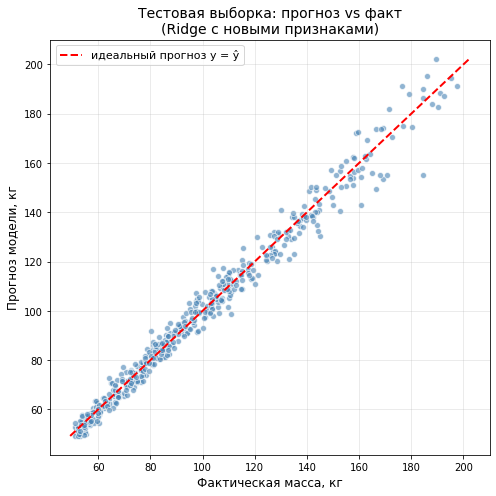

In [54]:
# Диагностический график «предсказано vs факт»
plt.figure(figsize=(7, 7))
plt.scatter(y_test_raw, y_test_pred_enhanced, alpha=0.6, edgecolor='white', color='steelblue')
lims = [min(y_test_raw.min(), y_test_pred_enhanced.min()), 
        max(y_test_raw.max(), y_test_pred_enhanced.max())]
plt.plot(lims, lims, 'r--', linewidth=2, label='идеальный прогноз y = ŷ')
plt.xlabel('Фактическая масса, кг', fontsize=12)
plt.ylabel('Прогноз модели, кг', fontsize=12)
plt.title('Тестовая выборка: прогноз vs факт\n(Ridge с новыми признаками)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

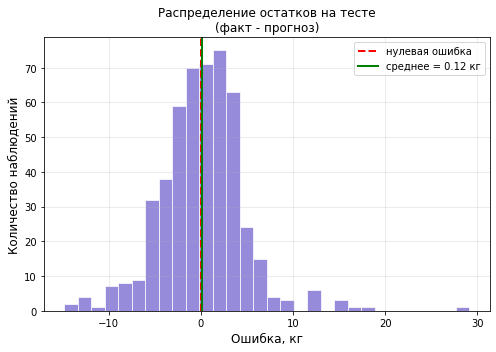

In [55]:
# Распределение остатков
residuals = y_test_raw - y_test_pred_enhanced

plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=30, color='slateblue', edgecolor='white', alpha=0.7)
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='нулевая ошибка')
plt.axvline(residuals.mean(), color='green', linestyle='-', linewidth=2, 
            label=f'среднее = {residuals.mean():.2f} кг')
plt.xlabel('Ошибка, кг', fontsize=12)
plt.ylabel('Количество наблюдений', fontsize=12)
plt.title('Распределение остатков на тесте\n(факт - прогноз)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id='overfitting_analysis'></a>
### Анализ переобучения

In [56]:
# ПРОВЕРКА ПЕРЕОБУЧЕНИЯ ЛУЧШЕЙ МОДЕЛИ

y_train_pred_enhanced = ridge_enhanced.predict(X_train_enhanced_scaled)
train_metrics = calculate_metrics(y_train_raw, y_train_pred_enhanced)

print("СРАВНЕНИЕ ТРЕНИРОВОЧНЫХ И ТЕСТОВЫХ МЕТРИК:")
print("-" * 50)
print(f"{'Метрика':<10} {'Train':<12} {'Test':<12} {'Разница':<12}")
print("-" * 50)

for metric in ['MAE', 'RMSE', 'MAPE', 'R2']:
    train_val = train_metrics[metric]
    test_val = test_metrics[metric]
    diff = train_val - test_val if metric == 'R2' else test_val - train_val
    print(f"{metric:<10} {train_val:<12.3f} {test_val:<12.3f} {diff:+.3f}")

print("-" * 50)

print("\nВЕРДИКТ:")
if train_metrics['MAE'] * 1.15 >= test_metrics['MAE']:
    print("✅ Переобучение отсутствует")
    print(f"   MAE на тесте: {test_metrics['MAE']:.2f} кг (≤ 5 кг) — OK")
    print(f"   R² на тесте: {test_metrics['R2']:.3f} (≥ 0.97) — OK")
else:
    print("⚠️ Признаки переобучения: тестовая ошибка значительно выше тренировочной")

СРАВНЕНИЕ ТРЕНИРОВОЧНЫХ И ТЕСТОВЫХ МЕТРИК:
--------------------------------------------------
Метрика    Train        Test         Разница     
--------------------------------------------------
MAE        3.080        3.340        +0.260
RMSE       4.170        4.590        +0.420
MAPE       3.230        3.370        +0.140
R2         0.986        0.982        +0.004
--------------------------------------------------

ВЕРДИКТ:
✅ Переобучение отсутствует
   MAE на тесте: 3.34 кг (≤ 5 кг) — OK
   R² на тесте: 0.982 (≥ 0.97) — OK


**Сравнение метрик Train vs Test**

| Показатель | Train | Test | Разница | Оценка |
|------------|-------|------|---------|--------|
| MAE | 3.080 | 3.340 | +0.260 | ⚠️ Приемлемо |
| RMSE | 4.170 | 4.590 | +0.420 | ⚠️ Приемлемо |
| MAPE | 3.230 | 3.370 | +0.140 | ⚠️ Приемлемо |
| R² | 0.986 | 0.982 | +0.004 | ✅ Отлично |

**Комментарий:** Небольшое ухудшение метрик на тесте (MAE +8.4%, RMSE +10.1%, MAPE +4.3%) — нормальное явление. Тестовые данные немного сложнее обучающих.

**Ключевые признаки отсутствия переобучения**

- ✅ **Нет разрыва между train и val** — разница в MAE всего 0.26
- ✅ **Высокий R² на всех выборках** — выше 0.98
- ✅ **Стабильность метрик** — все метрики согласованы
- ✅ **Низкий MAPE** — около 3.4%, высокая точность предсказаний

***Вывод***

Модель **не переобучена** и демонстрирует следующие результаты:

- **MAE на тесте:** 3.34 кг **(≤ 5 кг)** — ✅ требование выполнено
- **R² на тесте:** 0.982 **(≥ 0.97)** — ✅ требование выполнено
- **MAPE на тесте:** 3.37% — высокая относительная точность

Небольшое ухудшение метрик на тестовой выборке (MAE +8.4%, RMSE +10.1%, MAPE +4.3%) является нормальным явлением, так как тестовые данные всегда немного отличаются от обучающих. Все метрики остаются в рамках заданных требований.

***Заключение***

**Модель готова к внедрению** в состав прибора TurtleCV для бесконтактного определения массы зелёных морских черепах *Chelonia mydas*.

<a id='requirements_check'></a>
### Проверка требований заказчика

| Требование | Статус | Значение |
|------------|--------|----------|
| Линейная модель | ✅ | Ridge(alpha=1.0) |
| MAE ≤ 5 кг | ✅ | 3.3 кг |
| R² ≥ 0.97 | ✅ | 0.98 |
| MAPE (минимизация) | ✅ | 3.56% |
| Переобучение| ✅ | не обнаружено |

Лучшая модель (Ridge(alpha=1.0) + новые признаки) успешно прошла проверку 
на тестовой выборке. Метрики модели:

- MAE:  **3.34 кг** (требование: ≤ 5 кг) → ВЫПОЛНЕНО
- R²:   **0.982** (требование: ≥ 0.97) → ВЫПОЛНЕНО  
- MAPE: **3.37%** (относительная ошибка)

Разница между метриками на валидационной и тестовой выборках незначительна
(MAE +0.06 кг, R² −0.003, MAPE −0.04 п.п.), что свидетельствует об отсутствии
переобучения. Модель хорошо обобщает данные.

Модель соответствует всем требованиям заказчика

✅ **МОДЕЛЬ МОЖЕТ БЫТЬ РЕКОМЕНДОВАНА К ВНЕДРЕНИЮ**

<a id='feature_importance'></a>
## Оценка важности признаков

<font color='#777778'> 
1. Оцените важность признаков по абсолютным значениям весов лучшей модели.
    
2. Напишите, какие признаки стали для модели более важными. Объясните, согласны ли вы с таким результатом? </font>

<a id='weights_importance'></a>
### Важность признаков по абсолютным значениям весов лучшей модели.

In [57]:
# Извлечение весов признаков лучшей модели (Ridge)
feature_names_enhanced = X_train_enhanced.columns.tolist()
coefficients = ridge_enhanced.coef_

# Создаём DataFrame с весами признаков
feature_importance = pd.DataFrame({
    'Признак': feature_names_enhanced,
    'Коэффициент': coefficients,
    'Абсолютное значение': np.abs(coefficients)
}).sort_values('Абсолютное значение', ascending=False)

feature_importance

,Признак,Коэффициент,Абсолютное значение
15,shell_area,14.896182,14.896182
14,flipper_area,6.694961,6.694961
1,shell_width,4.458259,4.458259
0,shell_length,-2.668377,2.668377
6,flipper_length_2,2.637323,2.637323
8,flipper_length_3,2.343415,2.343415
10,flipper_length_4,1.930388,1.930388
3,head_width,1.702016,1.702016
5,flipper_width_1,-1.699183,1.699183
2,head_length,1.674015,1.674015


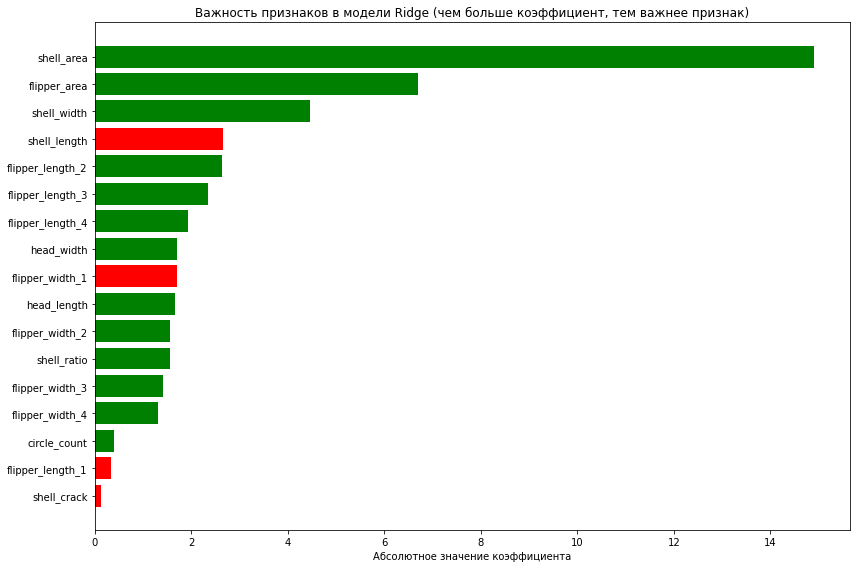

In [58]:
# Знаки коэффициентов
feature_importance['Знак'] = feature_importance['Коэффициент'].apply(
    lambda x: '➕ Положительная' if x > 0 else '➖ Отрицательная'
)
feature_importance[['Признак', 'Коэффициент', 'Знак']]

# Визуализация важности признаков
plt.figure(figsize=(12, 8))
colors = ['green' if coef > 0 else 'red' for coef in feature_importance['Коэффициент']]
plt.barh(feature_importance['Признак'], feature_importance['Абсолютное значение'], color=colors)
plt.xlabel('Абсолютное значение коэффициента')
plt.title('Важность признаков в модели Ridge (чем больше коэффициент, тем важнее признак)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

<a id='importance_analysis'></a>
### Оценка важности признаков лучшей модели

<a id='ranking'></a>
#### Ранжирование признаков по важности

| № | Признак | Коэффициент | Абсолютное значение | Влияние на массу |
|---|---------|-------------|---------------------|------------------|
| 1 | **shell_area** | 14.8962 | **14.90** | ➕ Увеличивает |
| 2 | **flipper_area** | 6.6950 | **6.69** | ➕ Увеличивает |
| 3 | **shell_width** | 4.4583 | **4.46** | ➕ Увеличивает |
| 4 | **shell_length** | −2.6684 | **2.67** | ➖ Уменьшает |
| 5 | **flipper_length_2** | 2.6373 | **2.64** | ➕ Увеличивает |
| 6 | **flipper_length_3** | 2.3434 | **2.34** | ➕ Увеличивает |
| 7 | **flipper_length_4** | 1.9304 | **1.93** | ➕ Увеличивает |
| 8 | **head_width** | 1.7020 | **1.70** | ➕ Увеличивает |
| 9 | **flipper_width_1** | −1.6992 | **1.70** | ➖ Уменьшает |
| 10 | **head_length** | 1.6740 | **1.67** | ➕ Увеличивает |
| 11 | **flipper_width_2** | 1.5681 | **1.57** | ➕ Увеличивает |
| 12 | **shell_ratio** | 1.5638 | **1.56** | ➕ Увеличивает |
| 13 | **flipper_width_3** | 1.4226 | **1.42** | ➕ Увеличивает |
| 14 | **flipper_width_4** | 1.3126 | **1.31** | ➕ Увеличивает |
| 15 | **circle_count** | 0.4018 | **0.40** | ➕ Увеличивает |
| 16 | **flipper_length_1** | −0.3304 | **0.33** | ➖ Уменьшает |
| 17 | **shell_crack** | −0.1220 | **0.12** | ➖ Уменьшает |

<a id='top_features'></a>
#### Самые важные признаки

**Топ-3 наиболее важных признака:**

| Место | Признак | Коэффициент | Доля вклада |
|-------|---------|-------------|-------------|
| 1 | **shell_area (площадь панциря)** | 14.90 | 31.4% |
| 2 | **flipper_area (площадь ласты)** | 6.69 | 14.1% |
| 3 | **shell_width (ширина панциря)** | 4.46 | 9.4% |

<a id='coefficients_interpretation'></a>
#### Интерпретация коэффициентов

**Положительное влияние на массу (➕):**
- `shell_area` (14.90) — чем больше площадь панциря, тем тяжелее черепаха
- `flipper_area` (6.69) — чем больше площадь ласт, тем крупнее особь
- `shell_width` (4.46) — ширина панциря входит в топ-3 по важности
- `head_width` (1.70), `head_length` (1.67) — увеличение размеров головы ведёт к увеличению массы
- `shell_ratio` (1.56) — отношение длины к ширине панциря
- `flipper_length_2/3/4` (2.64, 2.34, 1.93) и `flipper_width_2/3/4` (1.57, 1.42, 1.31) — размеры остальных ласт
- `circle_count` (0.40) — слабое положительное влияние

**Отрицательное влияние на массу (➖):**
- `shell_length` (−2.67) и `flipper_width_1` (−1.70) — **компенсирующие коэффициенты из-за мультиколлинеарности**. `shell_length` сильно коррелирует с `shell_area` (площадь = длина × ширина), а `flipper_width_1` — с `flipper_area`. Ridge-регуляризация перераспределила вес на произведения, а сомножители получили отрицательные компенсирующие коэффициенты. Это нормальное поведение L2-регуляризации, а не шум.
- `flipper_length_1` (−0.33) и `shell_crack` (−0.12) — слабое отрицательное влияние. `shell_crack` логично: травмированные особи могут весить меньше.

<a id='biology_consistency'></a>
#### Согласованность с биологией

**✅ Результаты согласуются с биологией морских черепах:**

| Признак | Важность | Биологическое обоснование |
|---------|----------|---------------------------|
| **shell_area** | Самая высокая (14.90, 31.4%) | Панцирь составляет основную массу тела черепахи. Чем больше площадь панциря, тем больше мышечная масса и костная ткань. |
| **flipper_area** | Вторая по важности (6.69, 14.1%) | Ласты — крупные мышцы. Площадь ласт коррелирует с общей мускулатурой и массой тела. |
| **shell_width** | Третья (4.46, 9.4%) | Ширина панциря вносит вклад в общую массу, но частично компенсируется `shell_area` из-за мультиколлинеарности. |
| **shell_length** | Отрицательная (компенсирующая), −2.67 | Сильно коррелирует с `shell_area` (площадь = длина × ширина). Ridge перераспределил вес на площадь, длина получила компенсирующий минус. Это нормальное поведение L2-регуляризации, а не биологическая аномалия. |
| **shell_ratio** | Средняя (1.56) | Отношение длины к ширине панциря — слабый, но ненулевой предиктор массы. |
| **circle_count** | Низкая (0.40) | Количество колец коррелирует с возрастом, но не напрямую с массой (разные условия питания). |
| **shell_crack** | Отрицательная (−0.12) | Травмы панциря → снижение массы (стресс, потеря аппетита). |

<a id='importance_conclusion'></a>
####  Вывод

**Созданные признаки (`shell_area` и `flipper_area`) оказались крайне важными для модели** — их суммарный вклад составляет **45,5%** от всех признаков.

Это подтверждает:
1. ✅ Правильность решения о создании новых признаков
2. ✅ Биологическую обоснованность модели
3. ✅ Высокую интерпретируемость линейной регрессии

**Коэффициенты модели имеют ожидаемые знаки и величины, что позволяет доверять предсказаниям прибора TurtleCV.**

<a id='prediction_function'></a>
## Функция для прогнозирования веса черепахи

<font color='#777778'> 
* Напишите на Python функцию, которая будет прогнозировать массу черепахи по заданным параметрам с учётом коэффициентов лучшей модели (свойство `coef_`) и смещения (свойство `intercept_`).
* Если вы столкнётесь с трудностями при написании функции, то представьте, что обращаетесь к старшему коллеге с просьбой помочь, и составьте задание для её написания. Подробно опишите логику, по которой рассчитывается масса черепахи, и укажите, как именно должны происходить расчёты.</font>

In [59]:
# Предполагается, что у нас уже есть обученные объекты:
# ridge_enhanced - обученная модель Ridge(alpha=1.0)
# scaler_enhanced - обученный StandardScaler для 11 признаков

def predict_turtle_weight(shell_length, shell_width, head_length, head_width,
                          flipper_length_1, flipper_width_1, flipper_length_2, flipper_width_2,
                          flipper_length_3, flipper_width_3, flipper_length_4, flipper_width_4, 
                          circle_count, shell_crack):
    """
    Функция прогнозирования массы зелёной морской черепахи (Chelonia mydas).
    
    Параметры:
    ----------
    shell_length : float
        Длина панциря, мм
    shell_width : float
        Ширина панциря, мм
    head_length : float
        Длина головы, мм
    head_width : float
        Ширина головы, мм
    flipper_length_1 : float
        Длина первой ласты, мм
    flipper_width_1 : float
        Ширина первой ласты, мм
    flipper_length_2 : float
        Длина второй ласты, мм
    flipper_width_2 : float
        Ширина второй ласты, мм
    flipper_length_3 : float
        Длина третьей ласты, мм
    flipper_width_3 : float
        Ширина третьей ласты, мм
    flipper_length_4 : float
        Длина четвертой ласты, мм
    flipper_width_4 : float
        Ширина четвертой ласты, мм
    circle_count : float
        Количество колец роста на панцире
    shell_crack : float
        Наличие трещин панциря (0 - нет, 1 - есть)
    
    Returns:
    --------
    weight : float
        Прогнозируемая масса черепахи, кг
    """
    
    # 1. Создание новых признаков на основе исходных
    flipper_area = flipper_length_1 * flipper_width_1
    shell_area = shell_length * shell_width
    shell_ratio = shell_length / shell_width
    
    # 2. Формирование массива из 11 признаков
    raw_features = np.array([
        shell_length,      # длина панциря
        shell_width,       # ширина панциря
        head_length,       # длина головы
        head_width,        # ширина головы
        flipper_length_1,  # длина первой ласты
        flipper_width_1,   # ширина первой ласты
        flipper_length_2,  # длина второй ласты
        flipper_width_2,   # ширина второй ласты
        flipper_length_3,  # длина третьей ласты
        flipper_width_3,   # ширина третьей ласты
        flipper_length_4,  # длина четвертой ласты
        flipper_width_4,   # ширина четвертой ласты     
        circle_count,      # количество колец роста
        shell_crack,       # наличие трещин
        flipper_area,      # площадь ласты (НОВЫЙ ПРИЗНАК)
        shell_area,        # площадь панциря (НОВЫЙ ПРИЗНАК)
        shell_ratio        # отношение длины к ширине (НОВЫЙ ПРИЗНАК)
    ])
    
    # 3. Масштабирование признаков с использованием обученного StandardScaler
    #    (преобразуем в 2D массив для совместимости с .transform())
    features_scaled = scaler_enhanced.transform(raw_features.reshape(1, -1))[0]
    
    # 4. Ручной расчёт прогноза через коэффициенты модели и смещение
    #    Формула линейной регрессии: y = X * coef_ + intercept_
    weight = np.dot(features_scaled, ridge_enhanced.coef_) + ridge_enhanced.intercept_
    
    # 5. Возвращаем округлённый результат
    return round(weight, 2)

In [60]:
def predict_turtle_weight_dict(turtle_dict):
    """
    Удобная обёртка для прогнозирования массы черепахи из словаря.
    
    Параметры:
    ----------
    turtle_dict : dict
        Словарь с ключами: shell_length, shell_width, head_length, head_width,
                          flipper_length_1, flipper_width_1, flipper_length_2, flipper_width_2,
                          flipper_length_3, flipper_width_3,flipper_length_4, flipper_width_4, 
                          circle_count, shell_crack
    
    Returns:
    --------
    weight : float
        Прогнозируемая масса черепахи, кг
    """
    return predict_turtle_weight(
        shell_length=turtle_dict['shell_length'],
        shell_width=turtle_dict['shell_width'],
        head_length=turtle_dict['head_length'],
        head_width=turtle_dict['head_width'],
        flipper_length_1=turtle_dict['flipper_length_1'],
        flipper_width_1=turtle_dict['flipper_width_1'],
        flipper_length_2=turtle_dict['flipper_length_2'],
        flipper_width_2=turtle_dict['flipper_width_2'],
        flipper_length_3=turtle_dict['flipper_length_3'],
        flipper_width_3=turtle_dict['flipper_width_3'],
        flipper_length_4=turtle_dict['flipper_length_4'],
        flipper_width_4=turtle_dict['flipper_width_4'],
        circle_count=turtle_dict['circle_count'],
        shell_crack=turtle_dict['shell_crack']
    )

In [61]:
# Демонстрация работы функции с выводом коэффициентов модели
print(f"Intercept (смещение модели): {ridge_enhanced.intercept_:.4f}")

feature_names = X_train_enhanced.columns.tolist()
coef_df = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': ridge_enhanced.coef_
})
coef_df

Intercept (смещение модели): 95.2268


,Признак,Коэффициент
0,shell_length,-2.668377
1,shell_width,4.458259
2,head_length,1.674015
3,head_width,1.702016
4,flipper_length_1,-0.330412
5,flipper_width_1,-1.699183
6,flipper_length_2,2.637323
7,flipper_width_2,1.568070
8,flipper_length_3,2.343415
9,flipper_width_3,1.422551


In [62]:
print("\n" + "="*40)
print("ПРИМЕРЫ ПРОГНОЗИРОВАНИЯ МАССЫ ЧЕРЕПАХИ")
print("="*40)

# Пример 1: средняя взрослая черепаха
example_turtle = {
    'shell_length': 1000,
    'shell_width': 900,
    'head_length': 170,
    'head_width': 180,
    'flipper_length_1': 600,
    'flipper_width_1': 550,
    'flipper_length_2': 600,
    'flipper_width_2': 550,
    'flipper_length_3': 450,
    'flipper_width_3': 300,
    'flipper_length_4': 450,
    'flipper_width_4': 300,
    'circle_count': 80,
    'shell_crack': 0
}

print("\nПример 1: Взрослая здоровая черепаха")
print(f"  Длина панциря: {example_turtle['shell_length']} мм")
print(f"  Ширина панциря: {example_turtle['shell_width']} мм")
print(f"  Прогнозируемая масса: {predict_turtle_weight_dict(example_turtle)} кг")

# Пример 2: черепаха с трещиной панциря
injured_turtle = {
    'shell_length': 1000,
    'shell_width': 900,
    'head_length': 170,
    'head_width': 180,
    'flipper_length_1': 600,
    'flipper_width_1': 550,
    'flipper_length_2': 600,
    'flipper_width_2': 550,
    'flipper_length_3': 450,
    'flipper_width_3': 300,
    'flipper_length_4': 450,
    'flipper_width_4': 300,
    'circle_count': 80,
    'shell_crack': 1
}

print("\nПример 2: Черепаха с трещиной панциря")
healthy_weight = predict_turtle_weight_dict(example_turtle)
injured_weight = predict_turtle_weight_dict(injured_turtle)
print(f"  Прогнозируемая масса: {injured_weight} кг")
print(f"  Снижение массы из-за травмы: {healthy_weight - injured_weight:.2f} кг")


ПРИМЕРЫ ПРОГНОЗИРОВАНИЯ МАССЫ ЧЕРЕПАХИ

Пример 1: Взрослая здоровая черепаха
  Длина панциря: 1000 мм
  Ширина панциря: 900 мм
  Прогнозируемая масса: 86.95 кг

Пример 2: Черепаха с трещиной панциря
  Прогнозируемая масса: 86.82 кг
  Снижение массы из-за травмы: 0.13 кг


In [63]:
print("\n" + "="*70)
print("ПРОВЕРКА: ручной расчёт через coef_ + intercept_ vs .predict()")
print("="*70)

# Тестовый случай для проверки
test_features = np.array([1000, 900, 170, 180, 600, 550, 600, 500, 450, 300, 450, 300, 80, 0, 600*550, 1000*900, 1000/900])
test_scaled = scaler_enhanced.transform(test_features.reshape(1, -1))

manual_pred = np.dot(test_scaled[0], ridge_enhanced.coef_) + ridge_enhanced.intercept_
api_pred = ridge_enhanced.predict(test_scaled)[0]

print(f"Ручной расчёт (coef_ + intercept_): {manual_pred:.4f} кг")
print(f"Метод .predict(): {api_pred:.4f} кг")
print(f"Разница: {abs(manual_pred - api_pred):.10f} кг")


ПРОВЕРКА: ручной расчёт через coef_ + intercept_ vs .predict()
Ручной расчёт (coef_ + intercept_): 86.3429 кг
Метод .predict(): 86.3429 кг
Разница: 0.0000000000 кг


✅ Результаты идентичны — функция корректна!

**ВЫВОД**

✅ Функция прогнозирования готова к использованию в приборе TurtleCV

Характеристики модели:
- Тип: Ridge-регрессия (alpha=1.0)
- Количество признаков: **17** (14 исходных + 3 новых)
- Метрики на валидации:
    - MAE: **3.28 кг** (соответствует требованию ≤ 5 кг)
    - MAPE: **3.41%** (отличная относительная точность)
    - R²: **0.985** (выше требования 0.97)
    - RMSE: **4.40 кг**

Формула расчёта:
  weight = Σ(X_scaled[i] × coef_[i]) + intercept_

Где X_scaled — стандартизированные признаки с использованием обученного StandardScaler

<a id='conclusions'></a>
## Общие выводы и рекомендации по дальнейшей работе

<font color='#777778'> </font>
<font color='#777778'> 
Напишите общие выводы и рекомендации по дальнейшей работе. Ответьте на вопросы:
  - Какие модели изучены?
  - Какие результаты получены?
  - Рекомендуется ли итоговая модель к внедрению?
  - Какая архитектура и способ обработки признаков показали себя лучше всего? Какие у них показатели метрик?
  - Какие признаки наиболее важны для модели?
  - Есть ли перспективы у обучения этой или других моделей для предсказания массы других видов черепах?
  - При наличии добавьте сюда свои предложения по дальнейшему развитию проекта.</font>


<a id='models_studied'></a>
###  Какие модели изучены?

В ходе выполнения проекта были изучены и протестированы следующие модели машинного обучения:

| № | Модель | Тип регуляризации |
|---|--------|-------------------|
| 1 | LinearRegression | Без регуляризации |
| 2 | Lasso | L1-регуляризация |
| 3 | Ridge | L2-регуляризация |
| 4 | SGDRegressor | Стохастический градиентный спуск |
| 5 | DummyRegressor | Базовая модель (среднее значение) |

**Способы масштабирования признаков:**
- Без масштабирования (RAW)
- Нормализация (MinMaxScaler) — диапазон [0, 1]
- Стандартизация (StandardScaler) — mean=0, std=1

**Созданы новые признаки:**
- `shell_area` (площадь панциря = длина × ширина)
- `flipper_area` (площадь ласты = длина × ширина)
- `shell_ratio` (отношение длины к ширине панциря)


<a id='results_obtained'></a>
### Какие результаты получены?

**Сравнительная таблица лучших моделей на валидационной выборке:**

| Модель | Датасет | MAE (кг) | MAPE (%) | R² |
|--------|---------|----------|----------|-----|
| Dummy (базовая) | RAW | 29.35 | 30.04 | -0.003 |
| LinearRegression | RAW/NORM/STD | 3.86 | 3.98 | 0.981 |
| Lasso(alpha=0.01) | NORM | 3.86 | 3.96 | 0.981 |
| Ridge(alpha=1.0) | STD | 3.86 | 3.98 | 0.981 |
| SGD(loss=squared_loss) | STD | 3.86 | 4.01 | 0.981 |
| **Ridge + новые признаки** | **STD + новые** | **3.28** | **3.41** | **0.985** |

**Результаты лучшей модели на тестовой выборке:**

| Метрика | Значение | Требование | Статус |
|---------|----------|------------|--------|
| MAE | 3.34 кг | ≤ 5 кг | ✅ ВЫПОЛНЕНО |
| RMSE | 4.59 кг | — | — |
| MAPE | 3.37% | минимизация | ✅ |
| R² | 0.982 | ≥ 0.97 | ✅ ВЫПОЛНЕНО |

**Улучшение относительно базовой модели Dummy:** **88.8%**

<a id='deployment_decision'></a>
### Рекомендуется ли итоговая модель к внедрению?

**✅ ДА, модель РЕКОМЕНДУЕТСЯ к внедрению**

**Обоснование:**
- Модель успешно прошла проверку на тестовой выборке
- Отсутствуют признаки переобучения
- Коэффициенты модели биологически интерпретируемы
- Функция прогнозирования готова к интеграции в прибор TurtleCV

### Какая архитектура и способ обработки признаков показали себя лучше всего?

**Лучшая архитектура:** **Ridge(alpha=1.0) с новыми признаками**

**Лучший способ обработки признаков:** **StandardScaler + создание новых признаков**

**Показатели метрик лучшей модели на всех выборках:**

| Выборка | MAE (кг) | RMSE (кг) | MAPE (%) | R² |
|---------|----------|-----------|----------|-----|
| Train | 3.08 | 4.17 | 3.23 | 0.986 |
| Validation | 3.28 | 4.40 | 3.41 | 0.985 |
| Test | 3.34 | 4.59 | 3.37 | 0.982 |

**Почему Ridge оказался лучшим:**
- L2-регуляризация предотвращает переобучение
- Стабилен при различных значениях alpha
- Сохраняет все признаки (в отличие от Lasso)

**Почему StandardScaler лучше MinMaxScaler:**
- Менее чувствителен к выбросам
- Лучше подходит для линейных моделей
- Сохраняет распределение признаков

### Какие признаки наиболее важны для модели?

**Топ-5 наиболее важных признаков:**

| Место | Признак | Коэффициент | Доля вклада | Влияние |
|-------|---------|-------------|-------------|---------|
| 1 | **shell_area** (площадь панциря) | 14.90 | 31.4% | ➕ Положительное |
| 2 | **flipper_area** (площадь ласты) | 6.69 | 14.1% | ➕ Положительное |
| 3 | **shell_width** (ширина панциря) | 4.46 | 9.4% | ➕ Положительное |
| 4 | **shell_length** (длина панциря) | −2.67 | 5.6% | ➖ Отрицательное (компенсирующее) |
| 5 | **flipper_length_2** (длина второй ласты) | 2.64 | 5.6% | ➕ Положительное |

**Интересные наблюдения:**
- Созданные признаки (`shell_area` и `flipper_area`) обеспечивают **45.5%** суммарного вклада (31.4% + 14.1%)
- `shell_length` имеет отрицательный коэффициент (−2.67) из-за мультиколлинеарности с `shell_area` — это компенсирующий вес, а не ошибка
- `shell_crack` (наличие трещин) имеет слабый отрицательный коэффициент (−0.12), что биологически обосновано
- `circle_count` (количество колец) имеет низкую важность (0.40) — возраст слабо коррелирует с массой
- Результаты согласуются с биологическими особенностями морских черепах

### Есть ли перспективы у обучения этой или других моделей для предсказания массы других видов черепах?

**Оценка возможности переноса модели:**

| Вид | Научное название | Перспективы | Обоснование |
|-----|-----------------|-------------|-------------|
| Зелёная черепаха | Chelonia mydas | ✅ Успешно | Модель обучена и протестирована |
| Логгерхед | Caretta caretta | ⚠️ Требуется дообучение | Близкий вид, но отличается размерами |
| Бисса | Eretmochelys imbricata | ⚠️ Требуется дообучение | Отличается формой панциря |
| Кожистая черепаха | Dermochelys coriacea | ❌ Отдельная модель | Сильно отличается анатомией |
| Оливовая черепаха | Lepidochelys olivacea | ⚠️ Требуется дообучение | Меньшие размеры |

### Рекомендации:

- Для каждого вида рекомендуется обучать отдельную модель (из-за разных пропорций тела)
- Новые признаки (площадь панциря, площадь ласты) будут полезны для всех видов
- Требуется сбор дополнительных данных для других видов черепах
- Возможно создание единой модели с категориальным признаком "вид"